# Remote Sensing Workflow

### Imports

In [2]:
# GIS and Spatial Data Libraries
import rasterio
from rasterio.transform import xy
from rasterio.warp import transform_bounds
from rasterio.plot import show

import geopandas as gpd
import shapely
from shapely.geometry import Point
from shapely.geometry import box
import rioxarray
import xrspatial as xspd
from pyproj import Transformer
import pip 
import json

# Data Analysis and Machine Learning
import numpy as np
import pandas as pd
from scipy.stats import skew

# Data Visualization
import matplotlib.pyplot as plt

# Print verification to ensure everything loaded without errors
print("All libraries imported successfully")

All libraries imported successfully


## Data Load

### OpenTopography DEM

In [3]:
# File Loading Validation
from pathlib import Path
import os

# Check for File Load Errors
print("Working directory:", Path.cwd())
print("Python executable:", os.sys.executable)
print("Datasets folder exists:", Path("Datasets").exists())

Working directory: c:\Users\matil\Documents\GitHub\GIS-Project
Python executable: c:\Users\matil\AppData\Local\Programs\Python\Python313\python.exe
Datasets folder exists: True


In [4]:
# File Load and Metadata Validation
DEM_path = r"Datasets\rasters_CAMRDEM\DEM.tif"

with rasterio.open(DEM_path) as DEM_src:
    elevation = DEM_src.read(1)
    elevation_transform = DEM_src.transform
    elevation_crs = DEM_src.crs

    file_name = os.path.basename(DEM_path)

    print(
            f"File: {file_name} | "
            f"Type: {type(elevation).__name__} | "
            f"Size: {elevation.size} | "
            f"Shape: {elevation.shape} | "
            f"Min: {elevation.min()} | "
            f"Max: {elevation.max()} | "
            f"NoData: {DEM_src.nodata} | "
            f"CRS: {DEM_src.crs} | "
            f"Resolution: {DEM_src.res}"
            f"Bounds: {DEM_src.bounds}"
        )       

File: DEM.tif | Type: ndarray | Size: 596070 | Shape: (895, 666) | Min: -32767.0 | Max: 1503.9169921875 | NoData: -32767.0 | CRS: EPSG:3979 | Resolution: (30.0, 30.0)Bounds: BoundingBox(left=-1980000.0, bottom=473550.0, right=-1960020.0, top=500400.0)


In [5]:
# AOI Bound Conversion
bounds_EPSG_4326 = transform_bounds(
    DEM_src.crs,
    "EPSG:4326",
    *DEM_src.bounds
)

bounds_EPSG_32610 = transform_bounds(
    DEM_src.crs,
    "EPSG:32610",
    *DEM_src.bounds
)

print(
    f"EPSG:3979: {DEM_src.bounds}\n"
    f"EPSG:4326: {bounds_EPSG_4326 }\n"
    f"EPSG:32610: {bounds_EPSG_32610}" 
)

EPSG:3979: BoundingBox(left=-1980000.0, bottom=473550.0, right=-1960020.0, top=500400.0)
EPSG:4326: (-123.29291260026993, 49.25527457420543, -122.8853009908351, 49.55076853448343)
EPSG:32610: (478779.52998752374, 5455842.720256816, 508333.4824226063, 5488685.934225603)


In [6]:
# Create .geojson for Bound Selection between Data Browsers
west, south, east, north = bounds_EPSG_4326

print(
    f"W: {bounds_EPSG_4326[0]}",
    f"S: {bounds_EPSG_4326[1]}",
    f"E: {bounds_EPSG_4326[2]}",
    f"N: {bounds_EPSG_4326[3]}",
)

geometry = box(west, south, east, north)

geojson = {
    "type": "FeatureCollection",
    "features": [{
        "type": "Feature",
        "properties": {},
        "geometry": geometry.__geo_interface__
    }]
}

with open("dem_AOI.geojson", "w") as f:
    json.dump(geojson, f, indent=2)

W: -123.29291260026993 S: 49.25527457420543 E: -122.8853009908351 N: 49.55076853448343


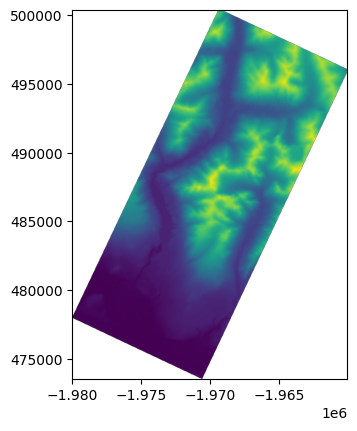

<Axes: >

In [7]:
# Data Mask fo NoData
valid_mask = elevation != DEM_src.nodata

elevation_valid = np.where(
    valid_mask,
    elevation,
    np.nan
)

# Data Plot for Export Validation
show(elevation_valid, transform=DEM_src.transform)

### EarthEngine Sentinel-2 & Dynamic World V1

In [9]:
# EE Authentication
import ee 

ee.Authenticate()
ee.Initialize(project="gis-project-510419")

In [10]:
# Bound Selection for General AOI
import pyproj
from pyproj import Transformer
transformer = pyproj.Transformer.from_crs("EPSG:32610", "EPSG:4326", always_xy=True)

xmin_geo, ymin_geo = transformer.transform(478779.52998752374, 5455842.720256816)
xmax_geo, ymax_geo = transformer.transform(508333.4824226063, 5488685.934225603)

#xmin_geo, ymin_geo = transformer.transform(399940.0, 5388440.0)
#xmax_geo, ymax_geo = transformer.transform(510170.0, 5501780.0)

print(
    f"xmin: {xmin_geo}", 
    f"ymin: {ymin_geo}", 
    f"xmax: {xmax_geo}", 
    f"ymax: {ymax_geo}"
)

aoi = ee.Geometry.Rectangle([
    xmin_geo,
    ymin_geo ,
    xmax_geo,
    ymax_geo
])

xmin: -123.29161663788408 ymin: 49.25498431356825 xmax: -122.88478957342635 ymax: 49.55071922714218


### Composites

In [11]:
def get_image_collection(year, aoi_bounds, tile, max_cloudy_pixels):
    return (
        ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterBounds(aoi_bounds)
        .filterDate(f"{year}-08-01",f"{year}-09-01")
        .filter(ee.Filter.eq('MGRS_TILE', tile))
        .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", max_cloudy_pixels))
    )

def add_band_names(image):
    return image.set("band_names", image.bandNames())

def get_crs(image):
    return image.set("crs", image.select("B4").projection().crs())

def scale_reflectance(image):
    scale_factor = 0.0001
    return image.multiply(scale_factor)

In [12]:
cloudy_pixels_percentage = 10
tile_type = '10UDV'

sentinel_2026_set = get_image_collection(2026, aoi, tile_type, cloudy_pixels_percentage)
sentinel_2025_set = get_image_collection(2025, aoi, tile_type, cloudy_pixels_percentage)
sentinel_2024_set = get_image_collection(2024, aoi, tile_type, cloudy_pixels_percentage)

In [13]:
def get_collection_metadata(image_collection):

    metadata =  {
        'No. of Images': image_collection.size().getInfo(),
        'system_index': image_collection.aggregate_array("system:index").getInfo(),
        'system_path': image_collection.aggregate_array('system:id').getInfo(),
        'band_names': image_collection.map(add_band_names).aggregate_array("band_names").getInfo(),
        'date': pd.to_datetime(image_collection.aggregate_array('system:time_start').getInfo(), unit="ms"),
        'crs': image_collection.map(get_crs).aggregate_array("crs").getInfo(),
        
        'PRODUCT_ID': image_collection.aggregate_array('PRODUCT_ID').getInfo(),
        'DATATAKE_IDENTIFIER': image_collection.aggregate_array('DATATAKE_IDENTIFIER').getInfo(),
        'MGRS_TILE': image_collection.aggregate_array('MGRS_TILE').getInfo(),
        'COVERAGE': f"{aoi.area(1).getInfo() / 1e6} km²",

        'CLOUDY_PIXEL_PERCENTAGE': image_collection.aggregate_array('CLOUDY_PIXEL_PERCENTAGE').getInfo(),
        'SENSING_ORBIT_NUMBER': image_collection.aggregate_array('SENSING_ORBIT_NUMBER').getInfo(),
        "MEAN_SOLAR_ZENITH_ANGLE": image_collection.aggregate_array("MEAN_SOLAR_ZENITH_ANGLE").getInfo(),
        "MEAN_SOLAR_AZIMUTH_ANGLE": image_collection.aggregate_array("MEAN_SOLAR_AZIMUTH_ANGLE").getInfo(),
    }

    return metadata

In [855]:
metadata_2026 = get_collection_metadata(sentinel_2026_set)
metadata_2025 = get_collection_metadata(sentinel_2025_set)
metadata_2024 = get_collection_metadata(sentinel_2024_set)

metadata_2026_df = pd.DataFrame(metadata_2026)
metadata_2025_df = pd.DataFrame(metadata_2025)
metadata_2024_df = pd.DataFrame(metadata_2024)

display(metadata_2026_df)
display(metadata_2025_df)
display(metadata_2024_df)

,No. of Images,system_index,system_path,band_names,date,crs,PRODUCT_ID,DATATAKE_IDENTIFIER,MGRS_TILE,COVERAGE,CLOUDY_PIXEL_PERCENTAGE,SENSING_ORBIT_NUMBER,MEAN_SOLAR_ZENITH_ANGLE,MEAN_SOLAR_AZIMUTH_ANGLE
0,6,20260805T191909_20260805T193001_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20260805T191909_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2026-08-05 19:30:54.598,EPSG:32610,S2B_MSIL2A_20260805T191909_N0512_R099_T10UDV_2...,GS2B_20260805T191909_049174_N05.12,10UDV,968.0252025383993 km²,0.000624,99,33.887102,158.400602
1,6,20260807T190911_20260807T191738_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20260807T190911_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2026-08-07 19:20:58.725,EPSG:32610,S2C_MSIL2A_20260807T190911_N0512_R056_T10UDV_2...,GS2C_20260807T190911_010036_N05.12,10UDV,968.0252025383993 km²,0.001403,56,35.053032,154.702427
2,6,20260812T190909_20260812T191707_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20260812T190909_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2026-08-12 19:20:56.841,EPSG:32610,S2B_MSIL2A_20260812T190909_N0512_R056_T10UDV_2...,GS2B_20260812T190909_049274_N05.12,10UDV,968.0252025383993 km²,5.967114,56,36.407918,155.700015
3,6,20260817T190911_20260817T191923_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20260817T190911_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2026-08-17 19:20:56.270,EPSG:32610,S2C_MSIL2A_20260817T190911_N0512_R056_T10UDV_2...,GS2C_20260817T190911_010179_N05.12,10UDV,968.0252025383993 km²,5.302232,56,37.848042,156.778319
4,6,20260820T191911_20260820T192259_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20260820T191911_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2026-08-20 19:30:51.723,EPSG:32610,S2C_MSIL2A_20260820T191911_N0512_R099_T10UDV_2...,GS2C_20260820T191911_010222_N05.12,10UDV,968.0252025383993 km²,0.003795,99,38.178547,161.253204
5,6,20260825T191909_20260825T192922_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20260825T191909_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2026-08-25 19:30:51.739,EPSG:32610,S2B_MSIL2A_20260825T191909_N0512_R099_T10UDV_2...,GS2B_20260825T191909_049460_N05.12,10UDV,968.0252025383993 km²,2.754107,99,39.770158,162.316087


,No. of Images,system_index,system_path,band_names,date,crs,PRODUCT_ID,DATATAKE_IDENTIFIER,MGRS_TILE,COVERAGE,CLOUDY_PIXEL_PERCENTAGE,SENSING_ORBIT_NUMBER,MEAN_SOLAR_ZENITH_ANGLE,MEAN_SOLAR_AZIMUTH_ANGLE
0,5,20250802T190931_20250802T191621_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20250802T190931_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2025-08-02 19:21:19.103,EPSG:32610,S2C_MSIL2A_20250802T190931_N0511_R056_T10UDV_2...,GS2C_20250802T190931_004745_N05.11,10UDV,968.0252025383993 km²,2.863577,56,33.831241,153.959003
1,5,20250810T191909_20250810T192442_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20250810T191909_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2025-08-10 19:30:57.008,EPSG:32610,S2B_MSIL2A_20250810T191909_N0511_R099_T10UDV_2...,GS2B_20250810T191909_044026_N05.11,10UDV,968.0252025383993 km²,0.001202,99,35.292058,159.345479
2,5,20250812T190931_20250812T191308_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20250812T190931_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2025-08-12 19:21:17.741,EPSG:32610,S2C_MSIL2A_20250812T190931_N0511_R056_T10UDV_2...,GS2C_20250812T190931_004888_N05.11,10UDV,968.0252025383993 km²,0.003149,56,36.451335,155.887888
3,5,20250822T190931_20250822T191956_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20250822T190931_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2025-08-22 19:21:18.207,EPSG:32610,S2C_MSIL2A_20250822T190931_N0511_R056_T10UDV_2...,GS2C_20250822T190931_005031_N05.11,10UDV,968.0252025383993 km²,0.001735,56,39.417989,158.105614
4,5,20250825T191931_20250825T192858_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20250825T191931_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2025-08-25 19:31:14.376,EPSG:32610,S2C_MSIL2A_20250825T191931_N0511_R099_T10UDV_2...,GS2C_20250825T191931_005074_N05.11,10UDV,968.0252025383993 km²,0.001954,99,39.830207,162.508912


,No. of Images,system_index,system_path,band_names,date,crs,PRODUCT_ID,DATATAKE_IDENTIFIER,MGRS_TILE,COVERAGE,CLOUDY_PIXEL_PERCENTAGE,SENSING_ORBIT_NUMBER,MEAN_SOLAR_ZENITH_ANGLE,MEAN_SOLAR_AZIMUTH_ANGLE
0,4,20240805T191909_20240805T192816_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20240805T191909_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2024-08-05 19:30:57.552,EPSG:32610,S2B_MSIL2A_20240805T191909_N0511_R099_T10UDV_2...,GS2B_20240805T191909_038735_N05.11,10UDV,968.0252025383993 km²,0.493453,99,34.008590,158.502368
1,4,20240807T190911_20240807T191924_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20240807T190911_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2024-08-07 19:20:59.643,EPSG:32610,S2A_MSIL2A_20240807T190911_N0511_R056_T10UDV_2...,GS2A_20240807T190911_047672_N05.11,10UDV,968.0252025383993 km²,0.143168,56,35.177987,154.801963
2,4,20240810T191911_20240810T191959_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20240810T191911_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2024-08-10 19:30:53.911,EPSG:32610,S2A_MSIL2A_20240810T191911_N0511_R099_T10UDV_2...,GS2A_20240810T191911_047715_N05.11,10UDV,968.0252025383993 km²,0.203406,99,35.359129,159.387264
3,4,20240830T191911_20240830T192023_T10UDV,COPERNICUS/S2_SR_HARMONIZED/20240830T191911_20...,"[B1, B2, B3, B4, B5, B6, B7, B8, B8A, B9, B11,...",2024-08-30 19:30:53.893,EPSG:32610,S2A_MSIL2A_20240830T191911_N0511_R099_T10UDV_2...,GS2A_20240830T191911_048001_N05.11,10UDV,968.0252025383993 km²,0.002077,99,41.588707,163.519978


In [15]:
def SCL_mask(image):
    scl = image.select("SCL")
    good_pixels = scl.gte(4).And(scl.lte(5))
    return image.updateMask(good_pixels)

def median_composite(images, band_list):
    SCL_masked_images = images.map(SCL_mask)
    band_masked_images = SCL_masked_images.select(band_list)
    scale_masked_images = band_masked_images.map(scale_reflectance)
    median_composite = scale_masked_images.median()

    source_projection = ee.Image(images.first()).select("B4").projection()

    return (
        scale_masked_images
        .median()
        .setDefaultProjection(source_projection)
    )

def ndvi(images):
    ndvi = images.normalizedDifference(["B8", "B4"])

    return ndvi

# Data
bands = ["B4", "B3", "B2", "B8"]
sentinel_datasets = [sentinel_2026_set, sentinel_2025_set, sentinel_2024_set]

# Composites
composite_2026 = median_composite(sentinel_2026_set, bands)
composite_2025 = median_composite(sentinel_2025_set, bands)
composite_2024 = median_composite(sentinel_2024_set, bands)

# NDVI
ndvi_2026 = ndvi(composite_2026)
ndvi_2025 = ndvi(composite_2025)
ndvi_2024 = ndvi(composite_2024)

# Export Composites
full_composite_2026 = composite_2026.addBands(ndvi_2026)
full_composite_2025 = composite_2025.addBands(ndvi_2025)
full_composite_2024 = composite_2024.addBands(ndvi_2024)

In [16]:
from IPython.display import Image, display
import requests

try:
    img = composite_2024
    url = img.select(["B4", "B3", "B2"]).getThumbURL({
        "region": aoi,                   
        "dimensions": 500,           
        "min": -1, 
        "max": 1,           
        "format": "png",
    })

    print(f"Generated URL: {url}\n")
    
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Server Error ({response.status_code}):")
        print(response.text) 
    else:
        print("URL is valid! Attempting display...")
        display(Image(url=url))

except Exception as e:
    print(f"Script execution failed: {e}")

Generated URL: https://earthengine.googleapis.com/v1/projects/gis-project-510419/thumbnails/c63ed6cf5b08e217dea88d905b6f248c-db04cce333722d8a96b221d859ca7132:getPixels

URL is valid! Attempting display...


In [ ]:
def task(export_bands, year, aoi_bounds, tile):
    export_task = ee.batch.Export.image.toDrive(
        image=export_bands,
        description=f"sentinel_l2a_{year}08_{tile}_composite",
        folder="EarthEngine",
        fileNamePrefix=f"sentinel_l2a_{year}08_{tile}_composite",
        region=aoi_bounds,
        scale=10,
        crs="EPSG:32610",
        maxPixels=1e9,
        fileFormat="GeoTIFF", 
        formatOptions={"noData": -9999},
    )

    export_task.start()
    print("Export started")
    return export_task

def sentinel_export(sentinel_bands):
    return sentinel_bands.select(
        ["B4", "B3", "B2", "B8", "nd"]
    ).toFloat()


In [ ]:
sentinel_2026_bands = sentinel_export(full_composite_2026)
sentinel_2025_bands = sentinel_export(full_composite_2025)
sentinel_2024_bands = sentinel_export(full_composite_2024)

task_2026 = task(sentinel_2026_bands, 2026, aoi, tile_type)
task_2025 = task(sentinel_2025_bands, 2025, aoi, tile_type)
task_2024 = task(sentinel_2024_bands, 2024, aoi, tile_type)

task_2026.status()
task_2025.status()
task_2024.status()

In [ ]:
def run_task(composite_bands):
    run_task = task(composite_bands, ) 

    

In [890]:
task_2026 = task(sentinel_2026_bands, 2026, aoi, tile_type)

Export started


In [909]:
print(task_2026.status()["state"])
task_2026.status()

COMPLETED


{'state': 'COMPLETED',
 'description': 'sentinel_l2a_202608_10UDV_composite',
 'priority': 100,
 'creation_timestamp_ms': 1793316513928,
 'update_timestamp_ms': 1793317095107,
 'start_timestamp_ms': 1793316693645,
 'task_type': 'EXPORT_IMAGE',
 'destination_uris': ['https://drive.google.com/#folders/16PMye91hB5cePcHjvv1Tr8_qE50-lc8r'],
 'attempt': 1,
 'batch_eecu_usage_seconds': 198.12545776367188,
 'id': 'XEJSCB2K7PJE3FP5QXNUN3JK',
 'name': 'projects/gis-project-510419/operations/XEJSCB2K7PJE3FP5QXNUN3JK'}

### Composite Data

In [709]:
def get_composite_data(ndvi_data_path):

    with rasterio.open(ndvi_data_path) as sentinel_src:

        bands = {
            "B4": sentinel_src.read(1),
            "B3": sentinel_src.read(2),
            "B2": sentinel_src.read(3),
            "B8_NIR": sentinel_src.read(4),
            "nd": sentinel_src.read(5),
        }

        raster_info = {
            "crs": sentinel_src.crs,
            "transform": sentinel_src.transform,
            "nodata": sentinel_src.nodatavals[0],
            "shape": sentinel_src.shape,
        }

        composite_metadata = {
            "File Name": os.path.basename(sentinel_src.name),
            "CRS": sentinel_src.crs,
            "Bounds": sentinel_src.bounds,
            "Width": sentinel_src.width,
            "Height": sentinel_src.height,
            "Tags": sentinel_src.tags(),
            "Resolution": sentinel_src.res,
            "NoData values": sentinel_src.nodatavals,
            "Transform": sentinel_src.transform,
            "Descriptions": sentinel_src.descriptions,
            "B4 Min/Max": (sentinel_2026_B4_R.min(), sentinel_2026_B4_R.max()),
            "B8 Min/Max": (sentinel_2026_B8_NIR.min(), sentinel_2026_B8_NIR.max()),
            "B2 Min/Max": (sentinel_2026_B2.min(), sentinel_2026_B2.max()),
            "B3 Min/Max": (sentinel_2026_B3.min(), sentinel_2026_B3.max()),
            "NDVI Min/Max": (sentinel_2026_nd.min(), sentinel_2026_nd.max()),
        }

    return {
        "bands": bands,
        "raster_info": raster_info, 
        "metadata": composite_metadata,
    }

In [ ]:
def get_ndvi(ndvi_data_path, crop_bounds):
    dataset = get_composite_data(ndvi_data_path)
    nd_band = dataset["bands"]["nd"]
    no_data_value = dataset["raster_info"]["nodata"]

    if no_data_value is None or np.isnan(no_data_value):
        no_data_mask = np.isfinite(nd_band)
    else:
        no_data_mask = ((nd_band != no_data_value) & np.isfinite(nd_band))

    dataset_clean = np.where(no_data_mask, nd_band, np.nan)
    dataset_crop = dataset_clean[crop_bounds]
    
    return dataset_crop

In [910]:
sentinel_ndvi_datasets = []
crop = (slice(row0, row1), slice(col0, col1))
years = range(2024, 2027)

for i in years:
    tif_path = rf"Datasets\sentinel_l2a_{i}08_10UDV_composite.tif"
    sentinel_ndvi_datasets.append(get_ndvi(tif_path, crop))

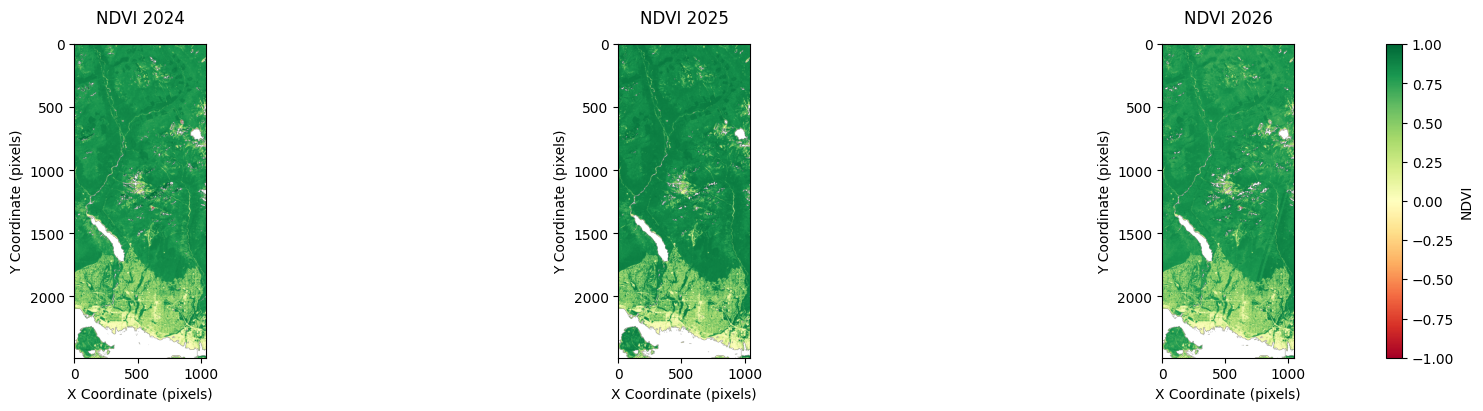

In [911]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), dpi=100, layout="constrained")

for ax, year, ndvi_data in zip(axes, years, sentinel_ndvi_datasets):
    image = ax.imshow(ndvi_data, cmap="RdYlGn", vmin=-1, vmax=1) 
    ax.set_title(f"NDVI {year}", pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

fig.colorbar(image, ax=axes, label="NDVI")
plt.show()

#### 2026 Sentinel Data

In [9]:
sentinel_2026 = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterDate("2026-08-1","2026-08-31")
    .filter(ee.Filter.eq('MGRS_TILE', '10UDV'))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 10))
)

print( 
    f"Number of images: {sentinel_2026.size().getInfo()}\n"
    f"Images: {sentinel_2026.aggregate_array("system:index").getInfo()}\n"
)

Number of images: 6
Images: ['20260805T191909_20260805T193001_T10UDV', '20260807T190911_20260807T191738_T10UDV', '20260812T190909_20260812T191707_T10UDV', '20260817T190911_20260817T191923_T10UDV', '20260820T191911_20260820T192259_T10UDV', '20260825T191909_20260825T192922_T10UDV']



In [10]:
# Inspect Metadata
sentinel_2026_image = ee.Image(sentinel_2026.toList(sentinel_2026.size()).get(1)) 

metadata = ee.Dictionary({
    'system_id': sentinel_2026_image .get('system:id'),
    'system_index': sentinel_2026_image .get('system:index'),
    'date': sentinel_2026_image .date().format('YYYY-MM-dd HH:mm:ss'),
    'bands': sentinel_2026_image .bandNames(),
    'projection': aoi.projection(),
    'PRODUCT_ID': sentinel_2026_image.get('PRODUCT_ID'),
    'DATATAKE_IDENTIFIER': sentinel_2026_image.get('DATATAKE_IDENTIFIER'),
    'MGRS_TILE': sentinel_2026_image.get('MGRS_TILE'),
    'CLOUDY_PIXEL_PERCENTAGE': sentinel_2026_image.get('CLOUDY_PIXEL_PERCENTAGE'),
    'SENSING_ORBIT_NUMBER': sentinel_2026_image.get('SENSING_ORBIT_NUMBER'),
    'COVERAGE': f"{aoi.area(1).getInfo() / 1e6} km²",
    "MEAN_SOLAR_ZENITH_ANGLE": sentinel_2026_image.get("MEAN_SOLAR_ZENITH_ANGLE").getInfo(),
    "MEAN_SOLAR_AZIMUTH_ANGLE": sentinel_2026_image.get("MEAN_SOLAR_AZIMUTH_ANGLE").getInfo()
})

info = metadata.getInfo()

for key, value in info.items():
    print(f"{key.upper()}: {value}")

CLOUDY_PIXEL_PERCENTAGE: 0.001403
COVERAGE: 12455.78868425222 km²
DATATAKE_IDENTIFIER: GS2C_20260807T190911_010036_N05.12
MEAN_SOLAR_AZIMUTH_ANGLE: 154.702427487952
MEAN_SOLAR_ZENITH_ANGLE: 35.0530318439777
MGRS_TILE: 10UDV
PRODUCT_ID: S2C_MSIL2A_20260807T190911_N0512_R056_T10UDV_20260807T234017
SENSING_ORBIT_NUMBER: 56
BANDS: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
DATE: 2026-08-07 19:20:58
PROJECTION: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
SYSTEM_ID: COPERNICUS/S2_SR_HARMONIZED/20260807T190911_20260807T191738_T10UDV
SYSTEM_INDEX: 20260807T190911_20260807T191738_T10UDV


In [318]:
from IPython.display import Image, display
import requests

try:
    img = sentinel_2026_image            
    url = img.select(["B4", "B3", "B2"]).getThumbURL({
        "region": aoi,                   
        "dimensions": 500,              
        "min": 0, 
        "max": 1500,           
        "format": "png",
    })

    print(f"Generated URL: {url}\n")
    
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Server Error ({response.status_code}):")
        print(response.text) 
    else:
        print("URL is valid! Attempting display...")
        display(Image(url=url))

except Exception as e:
    print(f"Script execution failed: {e}")

Generated URL: https://earthengine.googleapis.com/v1/projects/gis-project-510419/thumbnails/d69492ca12f5cb057f4ca2167e60f3e7-e4ceb25c0108eb45d0afc5584cd62071:getPixels

URL is valid! Attempting display...


In [12]:
sentinel_2026_bands = (
    sentinel_2026_image
    .select(["B4", "B8", "SCL", "B2", "B3"])
    .toUint16()
)

task = ee.batch.Export.image.toDrive(
    image=sentinel_2026_bands,
    description="sentinel_l2a_20260807T190911_20260807T191738_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20260807T190911_20260807T191738_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task.start()
print("Export started")

Export started


In [13]:
print(task.status())

{'state': 'READY', 'description': 'sentinel_l2a_20260807T190911_20260807T191738_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1792773568732, 'update_timestamp_ms': 1792773568732, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'RA55GMJDSV3E2SSXKCW2DV4F', 'name': 'projects/gis-project-510419/operations/RA55GMJDSV3E2SSXKCW2DV4F'}


In [674]:
sentinel_2026_data = r"Datasets\sentinel_l2a_202608_10UDV_composite.tif"

with rasterio.open(sentinel_2026_data) as sentinel_2026_src:
    # Read Band Data
    
    sentinel_2026_B4_R = sentinel_2026_src.read(1)
    sentinel_2026_B8_NIR = sentinel_2026_src.read(2)
    sentinel_2026_SCL = sentinel_2026_src.read(3)
    sentinel_2026_B2 = sentinel_2026_src.read(4)
    sentinel_2026_nd = sentinel_2026_src.read(5)

    # Dataset-level metadata
    sentinel_2026_B4_crs = sentinel_2026_src.crs
    sentinel_2026_B4_transform = sentinel_2026_src.transform
    sentinel_2026_B4_nodata = sentinel_2026_src.nodatavals[0]
    sentinel_2026_B4_shape = sentinel_2026_src.shape

    file_name_2026 = os.path.basename(sentinel_2026_src.name)

    print(
        f"File: {file_name_2026}\n"
        f"CRS: {sentinel_2026_src.crs}\n"
        f"Bounds: {sentinel_2026_src.bounds}\n"
        f"Width: {sentinel_2026_src.width}\n"
        f"Height: {sentinel_2026_src.height}\n"
        f"Tags: {sentinel_2026_src.tags()}\n"
        f"Resolution: {sentinel_2026_src.res}\n"
        f"NoData value: {sentinel_2026_src.nodatavals[0]}\n"
        f"Transform: {sentinel_2026_src.transform}\n"
        f"Descriptions: {sentinel_2026_src.descriptions}\n"
        f"B4 Min/Max: {sentinel_2026_B4_R.min()}/{sentinel_2026_B4_R.max()}\n"
        f"B8 Min/Max: {sentinel_2026_B8_NIR.min()}/{sentinel_2026_B8_NIR.max()}\n"
        f"B2 Min/Max: {sentinel_2026_B2.min()}/{sentinel_2026_B2.max()}\n"
        f"B3 Min/Max: {sentinel_2026_B3.min()}/{sentinel_2026_B3.max()}\n"
        f"SCL Min/Max: {sentinel_2026_SCL.min()}/{sentinel_2026_SCL.max()}"
    )

File: sentinel_l2a_202608_10UDV_composite.tif
CRS: EPSG:32610
Bounds: BoundingBox(left=478770.0, bottom=5455800.0, right=508390.0, top=5488730.0)
Width: 2962
Height: 3293
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: -9999.0
Transform: | 10.00, 0.00, 478770.00|
| 0.00,-10.00, 5488730.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B2', 'B3', 'B4', 'B8', 'NDVI')
B4 Min/Max: -9999.0/1.9452999830245972
B8 Min/Max: -9999.0/1.8301000595092773
B2 Min/Max: -9999.0/1.7187999486923218
B3 Min/Max: -9999.0/1.0
SCL Min/Max: -9999.0/1.7422000169754028


In [685]:
no_data_2026_sentinel = sentinel_2026_src.nodatavals[0]
no_data_2026_sentinel_mask = sentinel_2026_nd != no_data_2026_sentinel

ndvi_2026_sentinel = np.where(
    no_data_2026_sentinel_mask,
    sentinel_2026_nd,
    np.nan
)

ndvi_2026_sentinel.shape
ndvi_2026_crop_sentinel = ndvi_2026_sentinel[row0:row1, col0:col1]
print(ndvi_2026_crop_sentinel.shape)

print("NDVI source shape:", sentinel_2026_nd.shape)
print("Crop bounds:", row0, row1, col0, col1)
print("Requested crop shape:", row1 - row0, col1 - col0)

# Data Plot
plt.figure(figsize=(6, 4), dpi=100)
plt.imshow(ndvi_2026_crop_sentinel, cmap="RdYlGn", vmin=-1, vmax=1) 
plt.colorbar(label="NDVI")
plt.title("NDVI 2026", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

(2486, 1043)


In [682]:
print("NDVI source shape:", sentinel_2026_nd.shape)
print("Crop bounds:", row0, row1, col0, col1)
print("Requested crop shape:", row1 - row0, col1 - col0)

NDVI source shape: (3293, 2962)
Crop bounds: 401 2887 958 2001
Requested crop shape: 2486 1043


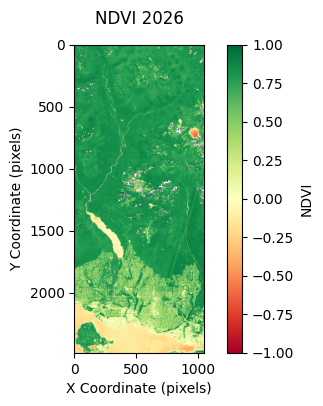

In [686]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=100)
plt.imshow(ndvi_2026_crop_sentinel, cmap="RdYlGn", vmin=-1, vmax=1) 
plt.colorbar(label="NDVI")
plt.title("NDVI 2026", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

In [15]:
# Sentinel-2 L2A SCL masking + NDVI
bad_classes_2026 = [0, 1, 2, 3, 6, 7, 8, 9, 10, 11]

# Keep only pixels that are not in the bad SCL classes
SCL_valid_mask_2026 = ~np.isin(sentinel_2026_SCL, bad_classes_2026)

# Mask red and NIR arrays using the valid SCL mask
sentinel_2026_B4_R_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B4_R,
    np.nan
)

sentinel_2026_B8_NIR_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B8_NIR,
    np.nan
)

sentinel_2026_B2_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B2,
    np.nan
)

sentinel_2026_B3_mask = np.where(
    SCL_valid_mask_2026,
    sentinel_2026_B3,
    np.nan
)

# Convert Sentinel-2 L2A DN to reflectance (0-1 scale)
sentinel_2026_B2_corrected = sentinel_2026_B2_mask * 0.0001
sentinel_2026_B3_corrected = sentinel_2026_B3_mask * 0.0001
sentinel_2026_B4_R_corrected = sentinel_2026_B4_R_mask * 0.0001
sentinel_2026_B8_NIR_corrected = sentinel_2026_B8_NIR_mask * 0.0001

denom_2026 = sentinel_2026_B4_R_corrected + sentinel_2026_B8_NIR_corrected

valid_reflectance_mask_2026 = (
    np.isfinite(sentinel_2026_B4_R_corrected)
    & np.isfinite(sentinel_2026_B8_NIR_corrected)
    & (sentinel_2026_B4_R_corrected >= 0)
    & (sentinel_2026_B8_NIR_corrected >= 0)
    & (denom_2026 > 1e-6)
)

# NDVI Calculation 
ndvi_2026 = np.full(sentinel_2026_B4_shape, np.nan, dtype=np.float32)

np.divide(
    sentinel_2026_B8_NIR_corrected - sentinel_2026_B4_R_corrected,
    denom_2026,
    out=ndvi_2026,
    where=valid_reflectance_mask_2026
)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(11334, 11023), dtype=float32)

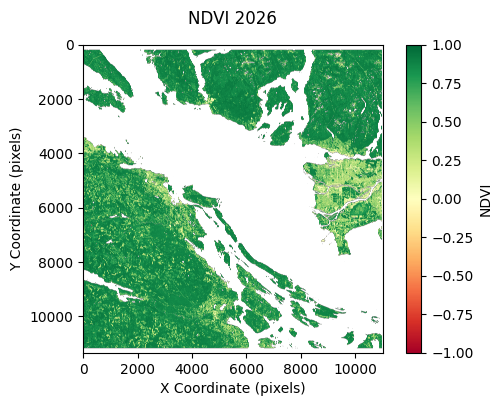

In [16]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=100)
plt.imshow(ndvi_2026, cmap="RdYlGn") 
plt.colorbar(label="NDVI")
plt.title("NDVI 2026", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

#### 2025 Sentinel Data

In [17]:
sentinel_2025 = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterDate("2025-08-1","2025-08-31")
    .filter(ee.Filter.eq('MGRS_TILE', '10UDV'))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 10))
)

print( 
    f"Number of images: {sentinel_2025.size().getInfo()}\n"
    f"Images: {sentinel_2025.aggregate_array("system:index").getInfo()}\n"
)

Number of images: 5
Images: ['20250802T190931_20250802T191621_T10UDV', '20250810T191909_20250810T192442_T10UDV', '20250812T190931_20250812T191308_T10UDV', '20250822T190931_20250822T191956_T10UDV', '20250825T191931_20250825T192858_T10UDV']



In [18]:
# Inspect Metadata
sentinel_2025_image = ee.Image(sentinel_2025.toList(sentinel_2025.size()).get(2)) 

metadata = ee.Dictionary({
    'system_id': sentinel_2025_image.get('system:id'),
    'system_index': sentinel_2025_image.get('system:index'),
    'date': sentinel_2025_image.date().format('YYYY-MM-dd HH:mm:ss'),
    'bands': sentinel_2025_image.bandNames(),
    'projection': aoi.projection(),
    'PRODUCT_ID': sentinel_2025_image.get('PRODUCT_ID'),
    'DATATAKE_IDENTIFIER': sentinel_2025_image.get('DATATAKE_IDENTIFIER'),
    'MGRS_TILE': sentinel_2025_image.get('MGRS_TILE'),
    'CLOUDY_PIXEL_PERCENTAGE': sentinel_2025_image.get('CLOUDY_PIXEL_PERCENTAGE'),
    'SENSING_ORBIT_NUMBER': sentinel_2025_image.get('SENSING_ORBIT_NUMBER'),
    'COVERAGE': f"{aoi.area(2).getInfo() / 1e6} km²",
    "MEAN_SOLAR_ZENITH_ANGLE": sentinel_2025_image.get("MEAN_SOLAR_ZENITH_ANGLE").getInfo(),
    "MEAN_SOLAR_AZIMUTH_ANGLE": sentinel_2025_image.get("MEAN_SOLAR_AZIMUTH_ANGLE").getInfo()
})

info = metadata.getInfo()

for key, value in info.items():
    print(f"{key.upper()}: {value}")

CLOUDY_PIXEL_PERCENTAGE: 0.003149
COVERAGE: 12455.78868425222 km²
DATATAKE_IDENTIFIER: GS2C_20250812T190931_004888_N05.11
MEAN_SOLAR_AZIMUTH_ANGLE: 155.887888351015
MEAN_SOLAR_ZENITH_ANGLE: 36.4513346780484
MGRS_TILE: 10UDV
PRODUCT_ID: S2C_MSIL2A_20250812T190931_N0511_R056_T10UDV_20250813T002416
SENSING_ORBIT_NUMBER: 56
BANDS: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
DATE: 2025-08-12 19:21:17
PROJECTION: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
SYSTEM_ID: COPERNICUS/S2_SR_HARMONIZED/20250812T190931_20250812T191308_T10UDV
SYSTEM_INDEX: 20250812T190931_20250812T191308_T10UDV


In [19]:
try:
    img = sentinel_2025_image            
    url = img.select(["B4", "B3", "B2"]).getThumbURL({
        "region": aoi,                   
        "dimensions": 500,              
        "min": 0, 
        "max": 1500,           
        "format": "png",
    })

    print(f"Generated URL: {url}\n")
    
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Server Error ({response.status_code}):")
        print(response.text) 
    else:
        print("URL is valid! Attempting display...")
        display(Image(url=url))

except Exception as e:
    print(f"Script execution failed: {e}")

Generated URL: https://earthengine.googleapis.com/v1/projects/gis-project-510419/thumbnails/24442a732b931f7ba6bcc09fc1bc17ef-6f9bd73af60e0332564c49b9bb769c3f:getPixels

URL is valid! Attempting display...


In [20]:
sentinel_2025_bands = (
    sentinel_2025_image
    .select(["B4", "B8", "SCL", "B2", "B3"])
    .toUint16()
)

task_2 = ee.batch.Export.image.toDrive(
    image=sentinel_2025_bands,
    description="sentinel_l2a_20250812T190931_20250812T191308_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20250812T190931_20250812T191308_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_2.start()
print("Export started")

Export started


In [21]:
print(task_2.status())

{'state': 'READY', 'description': 'sentinel_l2a_20250812T190931_20250812T191308_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1792773612217, 'update_timestamp_ms': 1792773612217, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'NQKVWK33G3XVNWE5JLR4NMDM', 'name': 'projects/gis-project-510419/operations/NQKVWK33G3XVNWE5JLR4NMDM'}


In [22]:
sentinel_2025_data = r"Datasets\sentinel_l2a_20250812T190931_20250812T191308_T10UDV.tif"

with rasterio.open(sentinel_2025_data) as sentinel_2025_src:
    # Read Band Data
    band_index = {name: i + 1 for i, name in enumerate(sentinel_2025_src.descriptions)}

    sentinel_2025_B4_R = sentinel_2025_src.read(band_index["B4"])
    sentinel_2025_B8_NIR = sentinel_2025_src.read(band_index["B8"])
    sentinel_2025_SCL = sentinel_2025_src.read(band_index["SCL"])
    sentinel_2025_B2 = sentinel_2025_src.read(band_index["B2"])
    sentinel_2025_B3 = sentinel_2025_src.read(band_index["B3"])

    # Dataset-level metadata
    sentinel_2025_B4_crs = sentinel_2025_src.crs
    sentinel_2025_B4_transform = sentinel_2025_src.transform
    sentinel_2025_B4_nodata = sentinel_2025_src.nodatavals[0]
    sentinel_2025_B4_shape = sentinel_2025_src.shape

    file_name_2025 = os.path.basename(sentinel_2025_src.name)

    print(
        f"File: {file_name_2025}\n"
        f"CRS: {sentinel_2025_src.crs}\n"
        f"Bounds: {sentinel_2025_src.bounds}\n"
        f"Width: {sentinel_2025_src.width}\n"
        f"Height: {sentinel_2025_src.height}\n"
        f"Tags: {sentinel_2025_src.tags()}\n"
        f"Resolution: {sentinel_2025_src.res}\n"
        f"NoData value: {sentinel_2025_src.nodatavals[0]}\n"
        f"Transform: {sentinel_2025_src.transform}\n"
        f"Descriptions: {sentinel_2025_src.descriptions}\n"
        f"B4 Min/Max: {sentinel_2025_B4_R.min()}/{sentinel_2025_B4_R.max()}\n"
        f"B8 Min/Max: {sentinel_2025_B8_NIR.min()}/{sentinel_2025_B8_NIR.max()}\n"
        f"B2 Min/Max: {sentinel_2025_B2.min()}/{sentinel_2025_B2.max()}\n"
        f"B3 Min/Max: {sentinel_2025_B3.min()}/{sentinel_2025_B3.max()}\n"
        f"SCL Min/Max: {sentinel_2025_SCL.min()}/{sentinel_2025_SCL.max()}"
    )

File: sentinel_l2a_20250812T190931_20250812T191308_T10UDV.tif
CRS: EPSG:32610
Bounds: BoundingBox(left=399940.0, bottom=5388440.0, right=510170.0, top=5501780.0)
Width: 11023
Height: 11334
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399940.00|
| 0.00,-10.00, 5501780.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B4', 'B8', 'SCL', 'B2', 'B3')
B4 Min/Max: 0/16328
B8 Min/Max: 0/15720
B2 Min/Max: 0/18072
B3 Min/Max: 0/17016
SCL Min/Max: 0/11


In [23]:
# Sentinel-2 L2A SCL masking + NDVI
bad_classes_2025 = [0, 1, 2, 3, 6, 7, 8, 9, 10, 11]

# Keep only pixels that are not in the bad SCL classes
SCL_valid_mask_2025 = ~np.isin(sentinel_2025_SCL, bad_classes_2025)

# Mask red and NIR arrays using the valid SCL mask
sentinel_2025_B4_R_mask = np.where(
    SCL_valid_mask_2025,
    sentinel_2025_B4_R,
    np.nan
)

sentinel_2025_B8_NIR_mask = np.where(
    SCL_valid_mask_2025,
    sentinel_2025_B8_NIR,
    np.nan
)

# Convert Sentinel-2 L2A DN to reflectance (0-1 scale)
sentinel_2025_B4_R_corrected = sentinel_2025_B4_R_mask * 0.0001
sentinel_2025_B8_NIR_corrected = sentinel_2025_B8_NIR_mask * 0.0001

denom_2025 = sentinel_2025_B4_R_corrected + sentinel_2025_B8_NIR_corrected
valid_reflectance_mask_2025 = (
    np.isfinite(sentinel_2025_B4_R_corrected)
    & np.isfinite(sentinel_2025_B8_NIR_corrected)
    & (sentinel_2025_B4_R_corrected >= 0)
    & (sentinel_2025_B8_NIR_corrected >= 0)
    & (denom_2025 > 1e-6)
)

# NDVI Calculation
ndvi_2025 = np.full(sentinel_2025_B4_shape, np.nan, dtype=np.float32)

np.divide(
    sentinel_2025_B8_NIR_corrected - sentinel_2025_B4_R_corrected,
    denom_2025,
    out=ndvi_2025,
    where=valid_reflectance_mask_2025
)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(11334, 11023), dtype=float32)

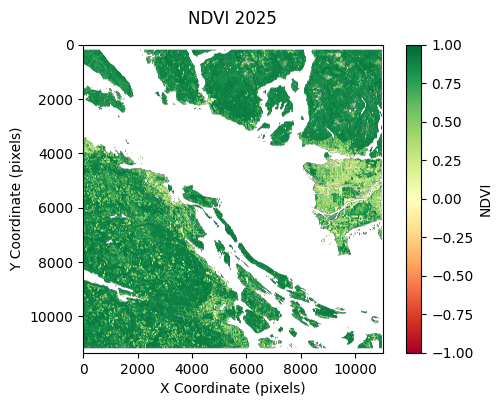

In [24]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=100)
plt.imshow(ndvi_2025, cmap="RdYlGn") 
plt.colorbar(label="NDVI")
plt.title("NDVI 2025", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

#### 2024 Sentinel Data

In [25]:
sentinel_2024 = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterDate("2024-08-1","2024-08-31")
    .filter(ee.Filter.eq('MGRS_TILE', '10UDV'))
    .filter(ee.Filter.lte("CLOUDY_PIXEL_PERCENTAGE", 10))
)

print( 
    f"Number of images: {sentinel_2024.size().getInfo()}\n"
    f"Images: {sentinel_2024.aggregate_array("system:index").getInfo()}\n"
)

Number of images: 5
Images: ['20240805T191909_20240805T192816_T10UDV', '20240807T190911_20240807T191924_T10UDV', '20240810T191911_20240810T191959_T10UDV', '20240810T191911_20240810T193052_T10UDV', '20240830T191911_20240830T192023_T10UDV']



In [26]:
# Inspect Metadata
sentinel_2024_image = ee.Image(sentinel_2024.toList(sentinel_2024.size()).get(1)) 

metadata = ee.Dictionary({
    'system_id': sentinel_2024_image.get('system:id'),
    'system_index': sentinel_2024_image.get('system:index'),
    'date': sentinel_2024_image.date().format('YYYY-MM-dd HH:mm:ss'),
    'bands': sentinel_2024_image.bandNames(),
    'projection': aoi.projection(),
    'PRODUCT_ID': sentinel_2024_image.get('PRODUCT_ID'),
    'DATATAKE_IDENTIFIER': sentinel_2024_image.get('DATATAKE_IDENTIFIER'),
    'MGRS_TILE': sentinel_2024_image.get('MGRS_TILE'),
    'CLOUDY_PIXEL_PERCENTAGE': sentinel_2024_image.get('CLOUDY_PIXEL_PERCENTAGE'),
    'SENSING_ORBIT_NUMBER': sentinel_2024_image.get('SENSING_ORBIT_NUMBER'),
    'COVERAGE': f"{aoi.area(2).getInfo() / 1e6} km²",
    "MEAN_SOLAR_ZENITH_ANGLE": sentinel_2024_image.get("MEAN_SOLAR_ZENITH_ANGLE").getInfo(),
    "MEAN_SOLAR_AZIMUTH_ANGLE": sentinel_2024_image.get("MEAN_SOLAR_AZIMUTH_ANGLE").getInfo()
})

info = metadata.getInfo()

for key, value in info.items():
    print(f"{key.upper()}: {value}")


CLOUDY_PIXEL_PERCENTAGE: 0.143168
COVERAGE: 12455.78868425222 km²
DATATAKE_IDENTIFIER: GS2A_20240807T190911_047672_N05.11
MEAN_SOLAR_AZIMUTH_ANGLE: 154.801962948294
MEAN_SOLAR_ZENITH_ANGLE: 35.1779869434921
MGRS_TILE: 10UDV
PRODUCT_ID: S2A_MSIL2A_20240807T190911_N0511_R056_T10UDV_20240808T020449
SENSING_ORBIT_NUMBER: 56
BANDS: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE']
DATE: 2024-08-07 19:20:59
PROJECTION: {'type': 'Projection', 'crs': 'EPSG:4326', 'transform': [1, 0, 0, 0, 1, 0]}
SYSTEM_ID: COPERNICUS/S2_SR_HARMONIZED/20240807T190911_20240807T191924_T10UDV
SYSTEM_INDEX: 20240807T190911_20240807T191924_T10UDV


In [27]:
try:
    img = sentinel_2024_image            
    url = img.select(["B4", "B3", "B2"]).getThumbURL({
        "region": aoi,                   
        "dimensions": 500,              
        "min": 0, 
        "max": 1500,           
        "format": "png",
    })

    print(f"Generated URL: {url}\n")
    
    response = requests.get(url)
    if response.status_code != 200:
        print(f"Server Error ({response.status_code}):")
        print(response.text) 
    else:
        print("URL is valid! Attempting display...")
        display(Image(url=url))

except Exception as e:
    print(f"Script execution failed: {e}")

Generated URL: https://earthengine.googleapis.com/v1/projects/gis-project-510419/thumbnails/7b4c1233bfc2f4114864df54e3d74dc9-8959641805f2c8dd92618b7965a75bfc:getPixels

URL is valid! Attempting display...


In [28]:
sentinel_2024_bands = (
    sentinel_2024_image
    .select(["B4", "B8", "SCL", "B2", "B3"])
    .toUint16()
)

task_3 = ee.batch.Export.image.toDrive(
    image=sentinel_2024_bands,
    description="sentinel_l2a_20240807T190911_20240807T191924_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="sentinel_l2a_20240807T190911_20240807T191924_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_3.start()
print("Export started")

Export started


In [29]:
print(task_3.status())

{'state': 'READY', 'description': 'sentinel_l2a_20240807T190911_20240807T191924_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1792773653745, 'update_timestamp_ms': 1792773653745, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'YW24ZZKSCURWO7T4GZFCOICV', 'name': 'projects/gis-project-510419/operations/YW24ZZKSCURWO7T4GZFCOICV'}


In [30]:
sentinel_2024_data = r"Datasets\sentinel_l2a_20240807T190911_20240807T191924_T10UDV.tif"

with rasterio.open(sentinel_2024_data) as sentinel_2024_src:
    # Read Band Data
    band_index = {name: i + 1 for i, name in enumerate(sentinel_2024_src.descriptions)}

    sentinel_2024_B4_R = sentinel_2024_src.read(band_index["B4"])
    sentinel_2024_B8_NIR = sentinel_2024_src.read(band_index["B8"])
    sentinel_2024_SCL = sentinel_2024_src.read(band_index["SCL"])
    sentinel_2024_B2 = sentinel_2024_src.read(band_index["B2"])
    sentinel_2024_B3 = sentinel_2024_src.read(band_index["B3"])

    # Dataset-level metadata
    sentinel_2024_B4_crs = sentinel_2024_src.crs
    sentinel_2024_B4_transform = sentinel_2024_src.transform
    sentinel_2024_B4_nodata = sentinel_2024_src.nodatavals[0]
    sentinel_2024_B4_shape = sentinel_2024_src.shape

    file_name_2024 = os.path.basename(sentinel_2024_src.name)

    print(
        f"File: {file_name_2024}\n"
        f"CRS: {sentinel_2024_src.crs}\n"
        f"Bounds: {sentinel_2024_src.bounds}\n"
        f"Width: {sentinel_2024_src.width}\n"
        f"Height: {sentinel_2024_src.height}\n"
        f"Tags: {sentinel_2024_src.tags()}\n"
        f"Resolution: {sentinel_2024_src.res}\n"
        f"NoData value: {sentinel_2024_src.nodatavals[0]}\n"
        f"Transform: {sentinel_2024_src.transform}\n"
        f"Descriptions: {sentinel_2024_src.descriptions}\n"
        f"B4 Min/Max: {sentinel_2024_B4_R.min()}/{sentinel_2024_B4_R.max()}\n"
        f"B8 Min/Max: {sentinel_2024_B8_NIR.min()}/{sentinel_2024_B8_NIR.max()}\n"
        f"B2 Min/Max: {sentinel_2024_B2.min()}/{sentinel_2024_B2.max()}\n"
        f"B3 Min/Max: {sentinel_2024_B3.min()}/{sentinel_2024_B3.max()}\n"
        f"SCL Min/Max: {sentinel_2024_SCL.min()}/{sentinel_2024_SCL.max()}"
    )

File: sentinel_l2a_20240807T190911_20240807T191924_T10UDV.tif
CRS: EPSG:32610
Bounds: BoundingBox(left=399940.0, bottom=5388440.0, right=510170.0, top=5501780.0)
Width: 11023
Height: 11334
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399940.00|
| 0.00,-10.00, 5501780.00|
| 0.00, 0.00, 1.00|
Descriptions: ('B4', 'B8', 'SCL', 'B2', 'B3')
B4 Min/Max: 0/17640
B8 Min/Max: 0/16536
B2 Min/Max: 0/20040
B3 Min/Max: 0/18648
SCL Min/Max: 0/11


In [31]:
# Sentinel-2 L2A SCL masking + NDVI using the correct sentinel_2_* variable names
bad_classes_2024 = [0, 1, 2, 3, 6, 7, 8, 9, 10, 11]

# Keep only pixels that are not in the bad SCL classes
SCL_valid_mask_2024 = ~np.isin(sentinel_2024_SCL, bad_classes_2024)

# Mask red and NIR arrays using the valid SCL mask
sentinel_2024_B4_R_mask = np.where(
    SCL_valid_mask_2024,
    sentinel_2024_B4_R,
    np.nan
)

sentinel_2024_B8_NIR_mask = np.where(
    SCL_valid_mask_2024,
    sentinel_2024_B8_NIR,
    np.nan
)

# Convert Sentinel-2 L2A DN to reflectance (0-1 scale)
sentinel_2024_B4_R_corrected = sentinel_2024_B4_R_mask * 0.0001
sentinel_2024_B8_NIR_corrected = sentinel_2024_B8_NIR_mask * 0.0001

denom_2024 = sentinel_2024_B4_R_corrected + sentinel_2024_B8_NIR_corrected
valid_reflectance_mask_2024 = (
    np.isfinite(sentinel_2024_B4_R_corrected)
    & np.isfinite(sentinel_2024_B8_NIR_corrected)
    & (sentinel_2024_B4_R_corrected >= 0)
    & (sentinel_2024_B8_NIR_corrected >= 0)
    & (denom_2024 > 1e-6)
)

# NDVI
ndvi_2024 = np.full(sentinel_2024_B4_shape, np.nan, dtype=np.float32)
np.divide(
    sentinel_2024_B8_NIR_corrected - sentinel_2024_B4_R_corrected,
    denom_2024,
    out=ndvi_2024,
    where=valid_reflectance_mask_2024
)

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(11334, 11023), dtype=float32)

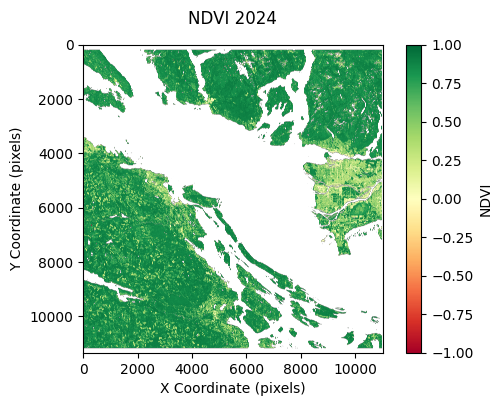

In [32]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=100)
plt.imshow(ndvi_2024, cmap="RdYlGn") 
plt.colorbar(label="NDVI")
plt.title("NDVI 2024", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### Dynamic World V1 Data 

In [33]:
dw = (
    ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1")
    .filterDate("2026-08-1", "2026-08-31")
    .filterBounds(aoi)
)

print( 
    f"Number of images: {dw.size().getInfo()}\n"
    f"Images: {dw.aggregate_array("system:index").getInfo()}\n"
)

Number of images: 70
Images: ['20260802T190919_20260802T191550_T10UCA', '20260802T190919_20260802T191550_T10UCU', '20260802T192841_20260802T193003_T10UCU', '20260805T191909_20260805T193001_T10UCA', '20260805T191909_20260805T193001_T10UCU', '20260805T191909_20260805T193001_T10UCV', '20260805T191909_20260805T193001_T10UDA', '20260805T191909_20260805T193001_T10UDU', '20260805T191909_20260805T193001_T10UDV', '20260805T191909_20260805T193001_T10UEA', '20260805T191909_20260805T193001_T10UEV', '20260807T190911_20260807T191738_T10UCA', '20260807T190911_20260807T191738_T10UCV', '20260807T190911_20260807T191738_T10UDA', '20260807T190911_20260807T191738_T10UDU', '20260807T190911_20260807T191738_T10UDV', '20260807T190911_20260807T191738_T10UEA', '20260807T190911_20260807T191738_T10UEU', '20260807T190911_20260807T191738_T10UEV', '20260810T191911_20260810T192806_T10UCA', '20260810T191911_20260810T192806_T10UDA', '20260810T191911_20260810T192806_T10UDU', '20260810T191911_20260810T192806_T10UDV', '202

In [34]:
dw_image = dw.filter(
    ee.Filter.eq(
        "system:index",
        "20260802T190919_20260802T191550_T10UCA"
    )
).first()

print( 
    f"image ID: {dw_image.getInfo()["id"]}\n"
    f"bands: {dw_image.bandNames().getInfo()}\n"
)

image ID: GOOGLE/DYNAMICWORLD/V1/20260802T190919_20260802T191550_T10UCA
bands: ['water', 'trees', 'grass', 'flooded_vegetation', 'crops', 'shrub_and_scrub', 'built', 'bare', 'snow_and_ice', 'label']



In [35]:
dw_label = dw_image.select("label")

task_4 = ee.batch.Export.image.toDrive(
    image=dw_label,
    description="dynamic_world_20260918_T10UDV",
    folder="EarthEngine",
    fileNamePrefix="dynamic_world_20260918_T10UDV",
    region=aoi,
    scale=10,
    crs="EPSG:32610",
    maxPixels=1e9
)

task_4.start()

print("Export started")

Export started


In [36]:
print(task_4.status())

{'state': 'READY', 'description': 'dynamic_world_20260918_T10UDV', 'priority': 100, 'creation_timestamp_ms': 1792773693364, 'update_timestamp_ms': 1792773693364, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': 'H4654C4RWV75SMAEL2JBODH6', 'name': 'projects/gis-project-510419/operations/H4654C4RWV75SMAEL2JBODH6'}


In [37]:
dynamic_world_tif_path = r"Dynamic_World_tif\dynamic_world_20260918_T10UDV.tif"

with rasterio.open(dynamic_world_tif_path) as dw_src:
    dw_data = dw_src.read(1)
    dw_crs = dw_src.crs
    dw_transform = dw_src.transform

    file_name_dw = os.path.basename(dw_src.name)

    print(
        f"File: {file_name_dw}\n"
        f"CRS: {dw_src.crs}\n"
        f"Bounds: {dw_src.bounds}\n"
        f"Width: {dw_src.width}\n"
        f"Height: {dw_src.height}\n"
        f"Tags: {dw_src.tags()}\n"
        f"Resolution: {dw_src.res}\n"
        f"NoData value: {dw_src.nodata}\n"
        f"Transform: {dw_src.transform}"
    )

File: dynamic_world_20260918_T10UDV.tif
CRS: EPSG:32610
Bounds: BoundingBox(left=399950.0, bottom=5389330.0, right=509960.0, top=5500900.0)
Width: 11001
Height: 11157
Tags: {'AREA_OR_POINT': 'Area'}
Resolution: (10.0, 10.0)
NoData value: None
Transform: | 10.00, 0.00, 399950.00|
| 0.00,-10.00, 5500900.00|
| 0.00, 0.00, 1.00|


In [51]:
from rasterio.warp import reproject, Resampling

dw_reproject = np.empty(sentinel_2026_B4_shape, dtype=np.float32)

reproject(
    source=dw_data,
    destination=dw_reproject,
    src_transform=dw_transform,
    src_crs=dw_crs,
    dst_transform=sentinel_2026_B4_transform,
    dst_crs=sentinel_2026_B4_crs,
    dst_nodata=np.nan,
    shape=sentinel_2026_B4_shape,
    resampling=Resampling.nearest
)

print(dw_reproject.shape)

(11334, 11023)


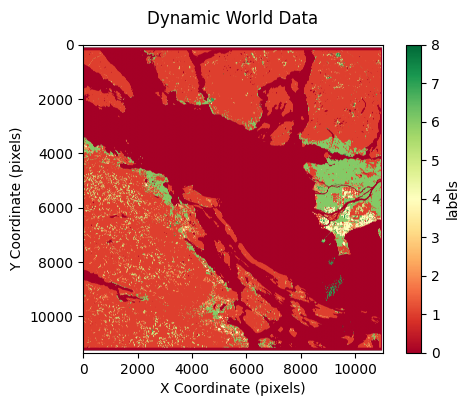

In [52]:
# Data Plot
plt.figure(figsize=(6, 4), dpi=100)
plt.imshow(dw_reproject, cmap="RdYlGn") 
plt.colorbar(label="labels")
plt.title("Dynamic World Data", pad=15)
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### DEM Reproject, Statistics, and Slope

In [675]:
from rasterio.warp import reproject, Resampling

elevation_reproject = np.empty(sentinel_2026_B4_shape, dtype=np.float32)

reproject(
    source=elevation_valid,
    destination=elevation_reproject,
    src_transform=elevation_transform,
    src_crs=elevation_crs,
    dst_transform=sentinel_2026_B4_transform,
    dst_crs=sentinel_2026_B4_crs,
    dst_nodata=np.nan,
    shape=sentinel_2026_B4_shape,
    resampling=Resampling.bilinear
)

print(elevation_reproject.shape)

(3293, 2962)


In [677]:
# Crop the reprojected DEM 
valid_DEM = np.isfinite(elevation_reproject)
rows, cols = np.where(valid_DEM)

if rows.size == 0:
    raise ValueError("elevation_reproject contains no finite data")

row0, row1 = rows.min(), rows.max() + 1  
col0, col1 = cols.min(), cols.max() + 1
elevation_crop = elevation_reproject[row0:row1, col0:col1]

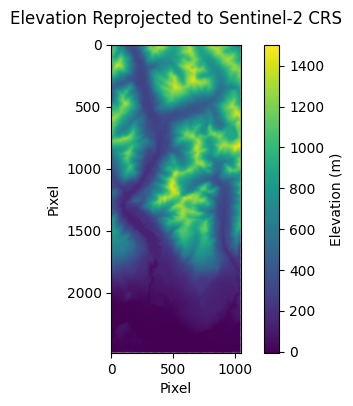

In [679]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=100)
im = ax.imshow(elevation_crop, cmap="viridis")
cbar = fig.colorbar(im, ax=ax, label="Elevation (m)")
ax.set_title("Elevation Reprojected to Sentinel-2 CRS", pad=15)
ax.set_xlabel("Pixel")
ax.set_ylabel("Pixel")
plt.show()

#### GDAL Slope

In [58]:
from osgeo import gdal
from affine import Affine

print(gdal.__version__)

3.13.3


In [1]:
# Create a GDAL in-memory dataset for the cropped DEM
dem_array = elevation_crop.astype(np.float32)
rows, cols = dem_array.shape

print("Rows:", rows)
print("Columns:", cols)

from osgeo import gdal

driver = gdal.GetDriverByName("MEM")
ds = driver.Create(
    "",
    cols,
    rows,
    1,
    gdal.GDT_Float32
)

# Translate the GDAL geotransform to match the cropped DEM's position in the original Sentinel-2 grid
crop_transform = sentinel_2026_B4_transform * Affine.translation(col0, row0)
ds.SetGeoTransform(crop_transform.to_gdal())
ds.SetProjection(sentinel_2026_B4_crs.to_wkt())

band = ds.GetRasterBand(1)
band.WriteArray(dem_array)
band.SetNoDataValue(np.nan)

slope_ds = gdal.DEMProcessing(
    "",
    ds,
    "slope",
    format="MEM",
    slopeFormat="degree",
    alg="Horn"
)

slope_band = slope_ds.GetRasterBand(1)
slope_gdal_array = slope_band.ReadAsArray()
slope_gdal_array = np.where(
    slope_gdal_array == -9999,
    np.nan,
    slope_gdal_array
)

NameError: name 'elevation_crop' is not defined

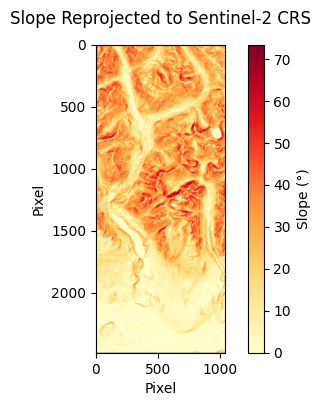

In [60]:
fig, ax = plt.subplots(figsize=(6,4), dpi=100)
im = ax.imshow(slope_gdal_array, cmap="YlOrRd")
cbar = fig.colorbar(im, ax=ax, label="Slope (°)")
ax.set_title("Slope Reprojected to Sentinel-2 CRS", pad=15)
ax.set_xlabel("Pixel")
ax.set_ylabel("Pixel")
plt.show()

### Temporal NDVI Change Statistics

In [61]:
ndvi_2024_crop = ndvi_2024[row0:row1, col0:col1]
ndvi_2025_crop = ndvi_2025[row0:row1, col0:col1]
ndvi_2026_crop = ndvi_2026[row0:row1, col0:col1]
dw_crop = dw_reproject[row0:row1, col0:col1]

print(
        f"NDVI 2024: {ndvi_2024_crop.shape}\n"
        f"NDVI 2025: {ndvi_2025_crop.shape}\n"
        f"NDVI 2026: {ndvi_2026_crop.shape}\n"
        f"DW V1: {dw_crop.shape}\n"
        f"DEM Reproject: {elevation_crop.shape}\n"
        f"Slope: {slope_gdal_array.shape}\n"
)

NDVI 2024: (2486, 1043)
NDVI 2025: (2486, 1043)
NDVI 2026: (2486, 1043)
DW V1: (2486, 1043)
DEM Reproject: (2486, 1043)
Slope: (2486, 1043)



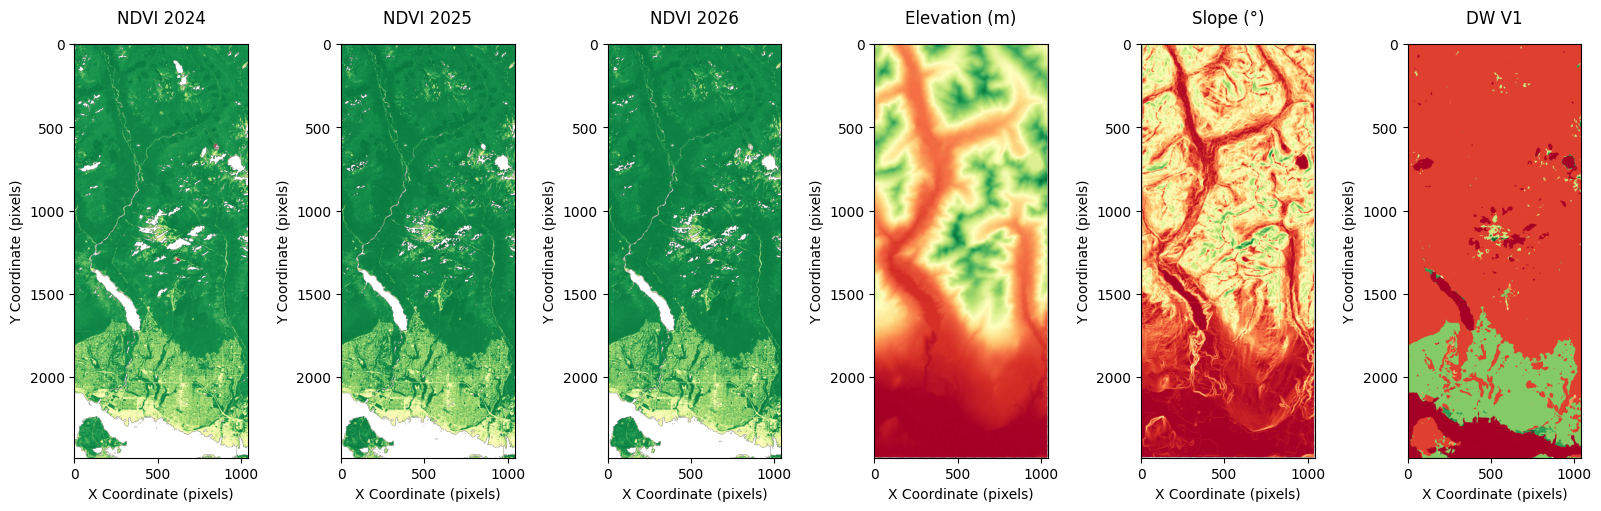

In [62]:
fig, axes = plt.subplots(1, 6, figsize=(16, 5), dpi=100, layout="constrained")
cmap = "RdYlGn"

datasets_full = [ndvi_2024_crop, ndvi_2025_crop, ndvi_2026_crop, elevation_crop, slope_gdal_array, dw_crop]
labels_full = ["NDVI 2024","NDVI 2025","NDVI 2026", "Elevation (m)", "Slope (°)", "DW V1"]

for ax, labels_full, datasets_full in zip(axes, labels_full, datasets_full):
    im = ax.imshow(datasets_full, cmap=cmap)
    ax.set_title(labels_full, pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

plt.show()

NDVI 2024 (Max, Min, Std, Mean, Med, Skew): [np.float32(1.0), np.float32(-1.0), np.float32(0.209), np.float32(0.745), np.float32(0.831), np.float32(-2.123)]
NDVI 2025 (Max, Min, Std, Mean, Med, Skew): [np.float32(1.0), np.float32(-1.0), np.float32(0.211), np.float32(0.774), np.float32(0.863), np.float32(-2.052)]
NDVI 2026 (Max, Min, Std, Mean, Med, Skew): [np.float32(1.0), np.float32(-1.0), np.float32(0.206), np.float32(0.775), np.float32(0.862), np.float32(-2.113)]
Elevation (m) (Max, Min, Std, Mean, Med, Skew): [np.float32(1503.237), np.float32(-5.149), np.float32(390.57), np.float32(523.092), np.float32(481.412), np.float32(0.269)]
Slope (°) (Max, Min, Std, Mean, Med, Skew): [np.float32(73.392), np.float32(0.0), np.float32(14.265), np.float32(19.49), np.float32(18.93), np.float32(0.273)]
DW V1 (Max, Min, Std, Mean, Med, Skew): [np.float32(8.0), np.float32(0.0), np.float32(1.974), np.float32(1.801), np.float32(1.0), np.float32(1.61)]


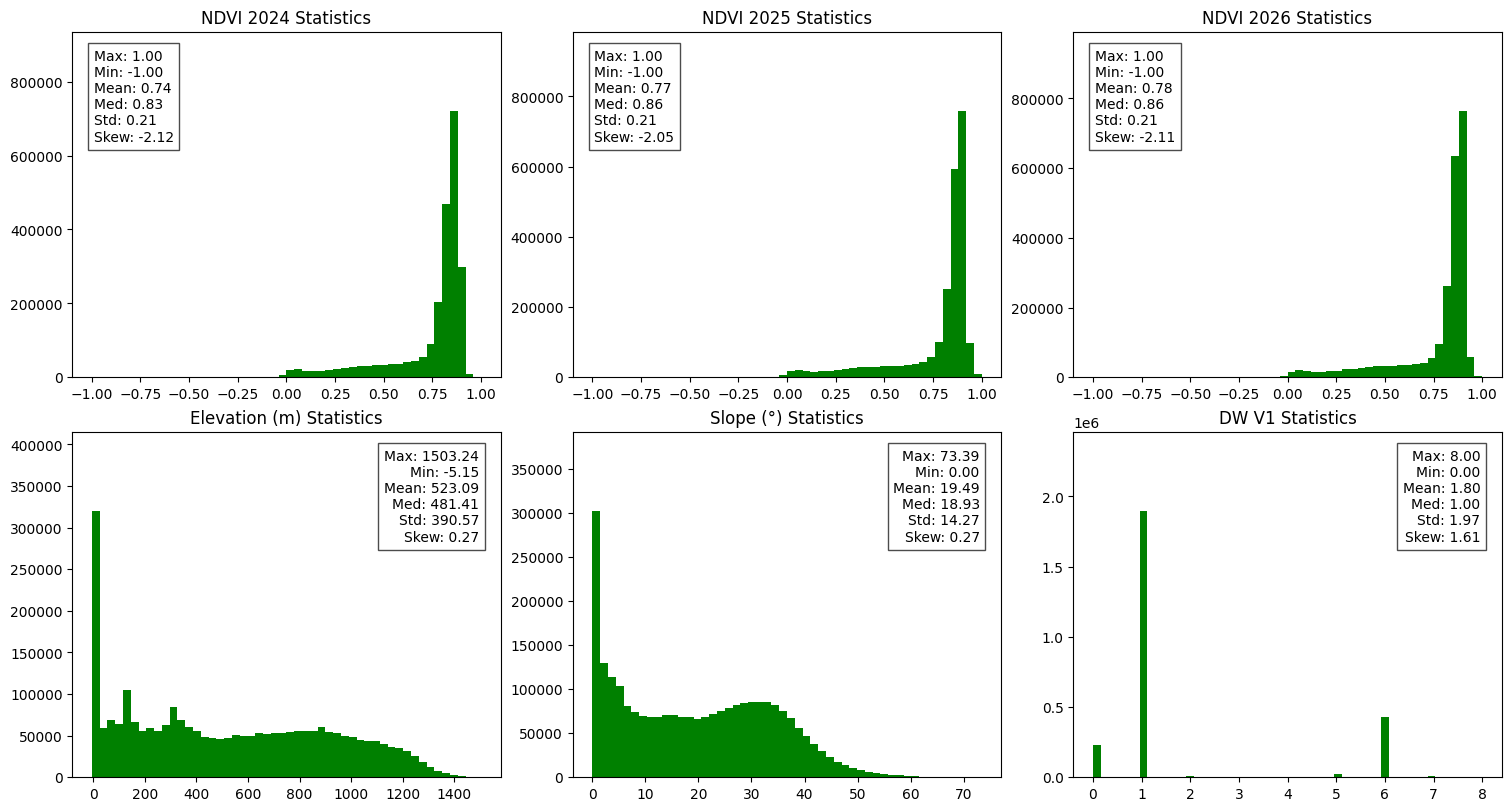

In [63]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), dpi=100, layout="constrained")
axes_flat = axes.flatten()

datasets = [ndvi_2024_crop, ndvi_2025_crop, ndvi_2026_crop, elevation_crop, slope_gdal_array, dw_crop]
data_labels = ["NDVI 2024", "NDVI 2025", "NDVI 2026", "Elevation (m)", "Slope (°)", "DW V1"]

for i, (label, data_matrix) in enumerate(zip(data_labels, datasets)):
    v = data_matrix.ravel()[np.isfinite(data_matrix.ravel())]
    stats = [v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v)]
    print(f"{label} (Max, Min, Std, Mean, Med, Skew):", [round(x, 3) for x in stats])
    
    counts, bins, patches = axes_flat[i].hist(v, bins=50, color="green")
    axes_flat[i].set_title(f"{label} Statistics")
    
    max_bar_height = counts.max()
    axes_flat[i].set_ylim(0, max_bar_height * 1.3)
    
    x_pos = 0.05 if i < 3 else 0.95
    h_align = 'left' if i < 3 else 'right'
    
    text = f"Max: {stats[0]:.2f}\nMin: {stats[1]:.2f}\nMean: {stats[3]:.2f}\nMed: {stats[4]:.2f}\nStd: {stats[2]:.2f}\nSkew: {stats[5]:.2f}"
    axes_flat[i].text(
        x_pos, 0.95, text, 
        transform=axes_flat[i].transAxes, 
        va='top', 
        ha=h_align, 
        bbox=dict(facecolor='white', alpha=0.7)
    )

plt.show()

In [107]:
valid_ndvi_temporal = np.isfinite(ndvi_2024_crop) & np.isfinite(ndvi_2025_crop) & np.isfinite(ndvi_2026_crop) 

def diff_ndvi(t_i, t_f):
    difference = np.full(t_i.shape, np.nan, dtype=np.float32)
    difference[valid_ndvi_temporal] = t_f[valid_ndvi_temporal] - t_i[valid_ndvi_temporal]

    return difference

diff_ndvi_2024_2025 = diff_ndvi(ndvi_2024_crop, ndvi_2025_crop)
diff_ndvi_2025_2026 = diff_ndvi(ndvi_2025_crop, ndvi_2026_crop)
diff_ndvi_2024_2026 = diff_ndvi(ndvi_2024_crop, ndvi_2026_crop)

2592898
2592898
2592898


2024–2025 NDVI (Max, Min, Std, Mean, Med, Skew, P05, P95): [np.float32(2.0), np.float32(-0.869), np.float32(0.048), np.float32(0.027), np.float32(0.025), np.float32(2.977), np.float32(-0.035), np.float32(0.093)]
2025–2026 NDVI (Max, Min, Std, Mean, Med, Skew, P05, P95): [np.float32(1.04), np.float32(-2.0), np.float32(0.039), np.float32(0.002), np.float32(-0.0), np.float32(-2.529), np.float32(-0.044), np.float32(0.06)]
2024–2026 NDVI (Max, Min, Std, Mean, Med, Skew, P05, P95): [np.float32(2.0), np.float32(-1.099), np.float32(0.045), np.float32(0.029), np.float32(0.025), np.float32(0.401), np.float32(-0.02), np.float32(0.094)]


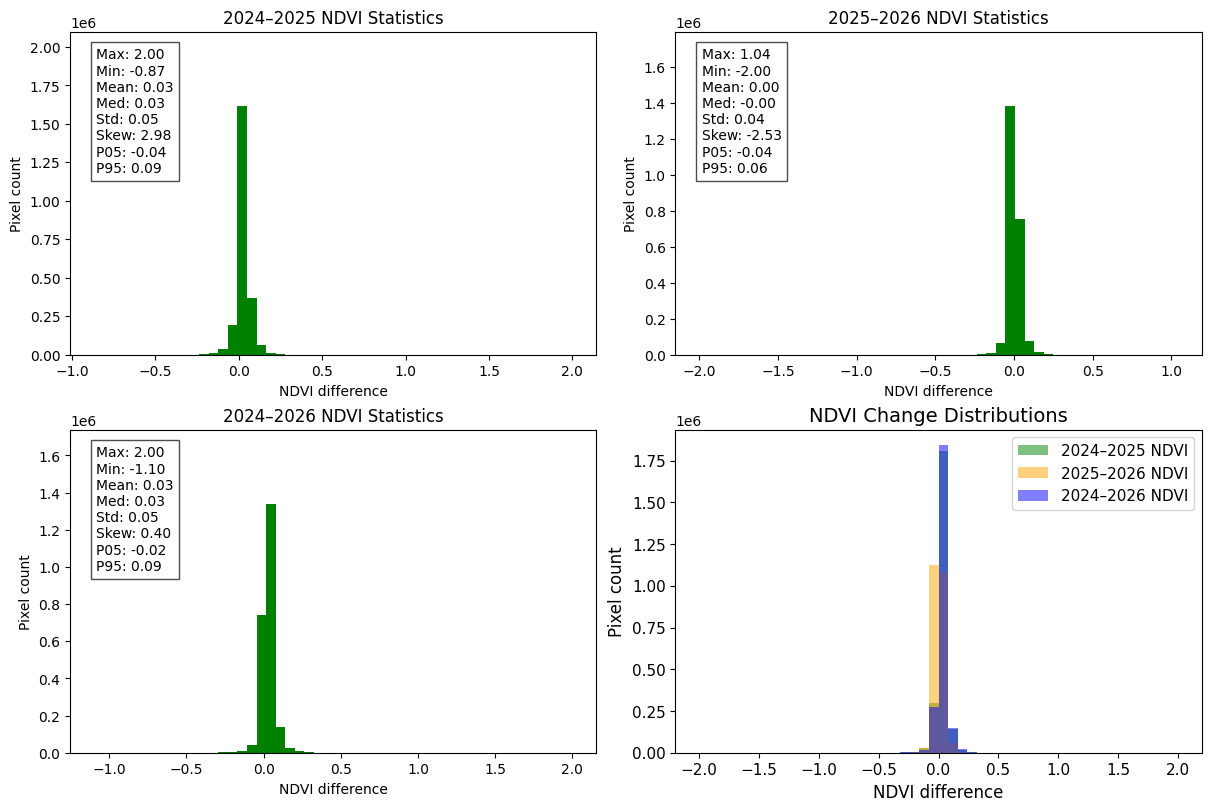

In [146]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), dpi=100, layout="constrained")
axes_flat = axes.flatten()

temporal_datasets = [
    diff_ndvi_2024_2025,
    diff_ndvi_2025_2026,
    diff_ndvi_2024_2026,
]
temporal_labels = ["2024–2025 NDVI", "2025–2026 NDVI", "2024–2026 NDVI"]

for i, (label, dataset) in enumerate(zip(temporal_labels, temporal_datasets)):
    v = dataset.ravel()[np.isfinite(dataset.ravel())]

    stats = [
        v.max(), v.min(), v.std(), v.mean(), np.median(v), skew(v),
        np.percentile(v, 5), np.percentile(v, 95)
    ]
    print(
        f"{label} (Max, Min, Std, Mean, Med, Skew, P05, P95):",
        [round(x, 3) for x in stats]
    )

    counts, bins, patches = axes_flat[i].hist(v, bins=50, color="green")
    axes_flat[i].set_title(f"{label} Statistics")
    axes_flat[i].set_xlabel("NDVI difference")
    axes_flat[i].set_ylabel("Pixel count")
    axes_flat[i].set_ylim(0, counts.max() * 1.3)

    text = (
        f"Max: {stats[0]:.2f}\n"
        f"Min: {stats[1]:.2f}\n"
        f"Mean: {stats[3]:.2f}\n"
        f"Med: {stats[4]:.2f}\n"
        f"Std: {stats[2]:.2f}\n"
        f"Skew: {stats[5]:.2f}\n"
        f"P05: {stats[6]:.2f}\n"
        f"P95: {stats[7]:.2f}"
    )

    axes_flat[i].text(
        0.05, 0.95, text,
        transform=axes_flat[i].transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", alpha=0.7)
    )

# Fourth panel: annual NDVI distributions on the shared valid pixels
change_data = [
    dataset.ravel()[np.isfinite(dataset.ravel())]
    for dataset in temporal_datasets
]

shared_bins = np.histogram_bin_edges(
    np.concatenate(change_data),
    bins=50,
)

for values, label, color in zip(
    change_data,
    temporal_labels,
    ["green", "orange", "blue"],
):
    axes_flat[3].hist(
        values,
        bins=shared_bins,
        color=color,
        alpha=0.5,
        label=label,
    )

axes_flat[3].set_xlabel("NDVI difference", fontsize=12)
axes_flat[3].set_ylabel("Pixel count", fontsize=12)
axes_flat[3].set_title("NDVI Change Distributions", fontsize=14)
axes_flat[3].tick_params(labelsize=11)
axes_flat[3].legend(fontsize=11)

plt.show()

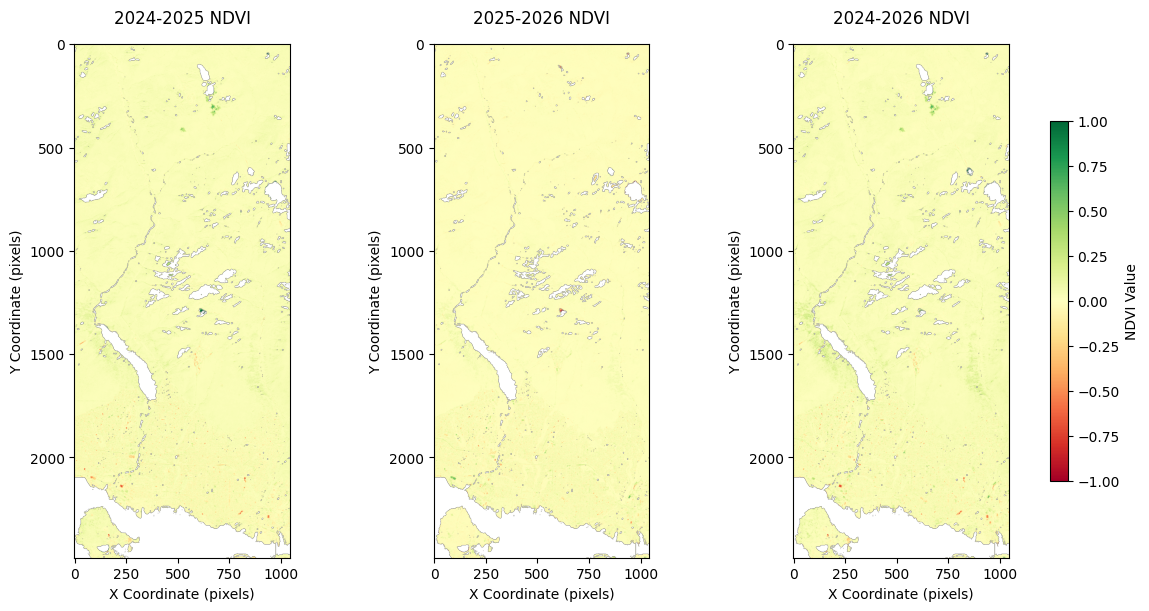

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), dpi=100, layout="constrained")

temporal_datasets = [diff_ndvi_2024_2025 , diff_ndvi_2025_2026, diff_ndvi_2024_2026]
temporal_labels = ["2024-2025 NDVI", "2025-2026 NDVI", "2024-2026 NDVI"]


for ax, temporal_labels, temporal_datasets in zip(axes, temporal_labels, temporal_datasets):
    im = ax.imshow(temporal_datasets, cmap=cmap, vmin=-1, vmax=1) # vmin=-1, vmax=1)
    ax.set_title(temporal_labels, pad=15)
    ax.set_xlabel("X Coordinate (pixels)")
    ax.set_ylabel("Y Coordinate (pixels)")

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="vertical", shrink=0.7, pad=0.03)
cbar.set_label("NDVI Value")
plt.show()

In [117]:
t = 0 
valid_pixel_count = np.count_nonzero(valid_ndvi_temporal)
print(valid_pixel_count)
print(valid_ndvi_temporal.size)
zero_count = np.count_nonzero(valid_ndvi_temporal == 0)
print(f"The raster contains {zero_count} zero pixels.")
 

ndvi_stats = pd.DataFrame({
    "Start mean NDVI": [
        np.mean(ndvi_2024_crop[valid_ndvi_temporal]),
        np.mean(ndvi_2025_crop[valid_ndvi_temporal]),
        np.mean(ndvi_2024_crop[valid_ndvi_temporal]),
    ],
    "End mean NDVI": [
        np.mean(ndvi_2025_crop[valid_ndvi_temporal]),
        np.mean(ndvi_2026_crop[valid_ndvi_temporal]),
        np.mean(ndvi_2026_crop[valid_ndvi_temporal]),
    ],
    "Mean NDVI change": [
        np.nanmean(diff_ndvi_2024_2025),
        np.nanmean(diff_ndvi_2025_2026),
        np.nanmean(diff_ndvi_2024_2026),
    ],
    "Percent change (%)": [
        100 * np.nanmean(diff_ndvi_2024_2025) / np.nanmean(ndvi_2024_crop),
        100 * np.nanmean(diff_ndvi_2025_2026) / np.nanmean(ndvi_2025_crop),
        100 * np.nanmean(diff_ndvi_2024_2026) / np.nanmean(ndvi_2024_crop),
    ],
    "Pixels increased": [
        np.sum(diff_ndvi_2024_2025 > t),
        np.sum(diff_ndvi_2025_2026 > t),
        np.sum(diff_ndvi_2024_2026 > t),
    ],
    "Pixels decreased": [
        np.sum(diff_ndvi_2024_2025 < t),
        np.sum(diff_ndvi_2025_2026 < t),
        np.sum(diff_ndvi_2024_2026 < t),
    ],

    "Pixels unchanged": [
        np.sum(np.abs(diff_ndvi_2024_2025) <= t),
        np.sum(np.abs(diff_ndvi_2025_2026) <= t),
        np.sum(np.abs(diff_ndvi_2024_2026) <= t),
    ],
     "Pixels increased (%)": [
        100 * np.sum(diff_ndvi_2024_2025 > t) / valid_pixel_count,
        100 * np.sum(diff_ndvi_2025_2026 > t) / valid_pixel_count,
        100 * np.sum(diff_ndvi_2024_2026 > t) / valid_pixel_count,
    ],
    "Pixels decreased (%)": [
        100 * np.sum(diff_ndvi_2024_2025 < t) / valid_pixel_count,
        100 * np.sum(diff_ndvi_2025_2026 < t) / valid_pixel_count,
        100 * np.sum(diff_ndvi_2024_2026 < t) / valid_pixel_count,
    ],
    "Pixels unchanged (%)": [
        100 * np.sum(np.abs(diff_ndvi_2024_2025) <= t) / valid_pixel_count,
        100 * np.sum(np.abs(diff_ndvi_2025_2026) <= t) / valid_pixel_count,
        100 * np.sum(np.abs(diff_ndvi_2024_2026) <= t) / valid_pixel_count,
    ],
    

}, index=[
    "2024 → 2025",
    "2025 → 2026",
    "2024 → 2026",
])

ndvi_stats

2310894
2592898


,Start mean NDVI,End mean NDVI,Mean NDVI change,Percent change (%),Pixels increased,Pixels decreased,Pixels unchanged,Pixels increased (%),Pixels decreased (%),Pixels unchanged (%)
2024 → 2025,0.746949,0.774150,0.027201,3.652761,1972826,337985,83,85.370683,14.625725,0.003592
2025 → 2026,0.774150,0.776099,0.001949,0.251860,1150222,1160449,223,49.773897,50.216453,0.009650
2024 → 2026,0.746949,0.776099,0.029150,3.914488,2014479,296335,80,87.173146,12.823392,0.003462


Pearson correlation (2024 vs. 2025): 0.974
Pearson correlation (2025 vs. 2026): 0.983
Pearson correlation (2024 vs. 2026): 0.975


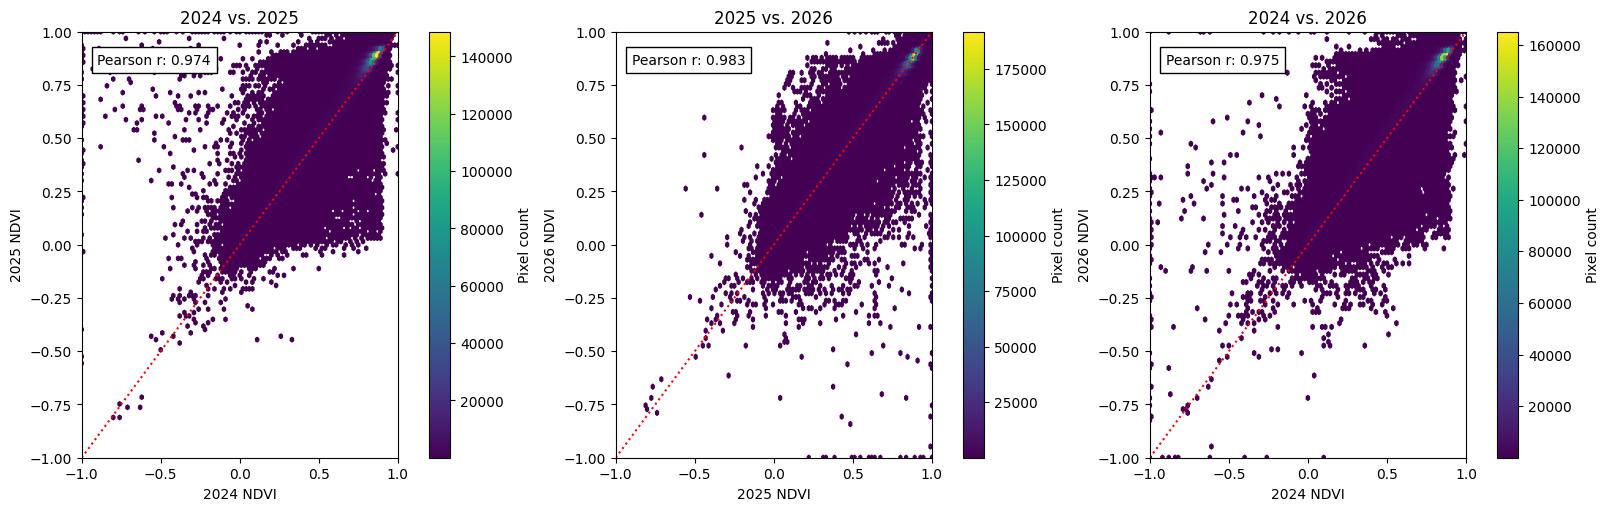

In [143]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=100, layout="constrained")

comparisons = [
    ("2024", "2025", ndvi_2024_crop, ndvi_2025_crop),
    ("2025", "2026", ndvi_2025_crop, ndvi_2026_crop),
    ("2024", "2026", ndvi_2024_crop, ndvi_2026_crop),
]

for ax, (year1, year2, ndvi1, ndvi2) in zip(axes, comparisons):
    x = ndvi1[valid_ndvi_temporal]
    y = ndvi2[valid_ndvi_temporal]
    P_coef = np.corrcoef(x, y)[0, 1]

    hb = ax.hexbin(x, y, gridsize=100, mincnt=1, cmap="viridis")
    fig.colorbar(hb, ax=ax, label="Pixel count")

    ax.plot([-1, 1], [-1, 1], "r:")
    ax.text(
        0.05, 0.95, f"Pearson r: {P_coef:.3f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="black", alpha=1),
    )
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_xlabel(f"{year1} NDVI")
    ax.set_ylabel(f"{year2} NDVI")
    ax.set_title(f"{year1} vs. {year2}")

    print(f"Pearson correlation ({year1} vs. {year2}): {P_coef:.3f}")

plt.show()

Pearson correlation (Elevation (m) vs. Slope (degrees)): 0.731 | Valid pixels: 2559049
Pearson correlation (2026 NDVI vs. Elevation (m)): 0.403 | Valid pixels: 2327228
Pearson correlation (2026 NDVI vs. Slope (degrees)): 0.432 | Valid pixels: 2317972


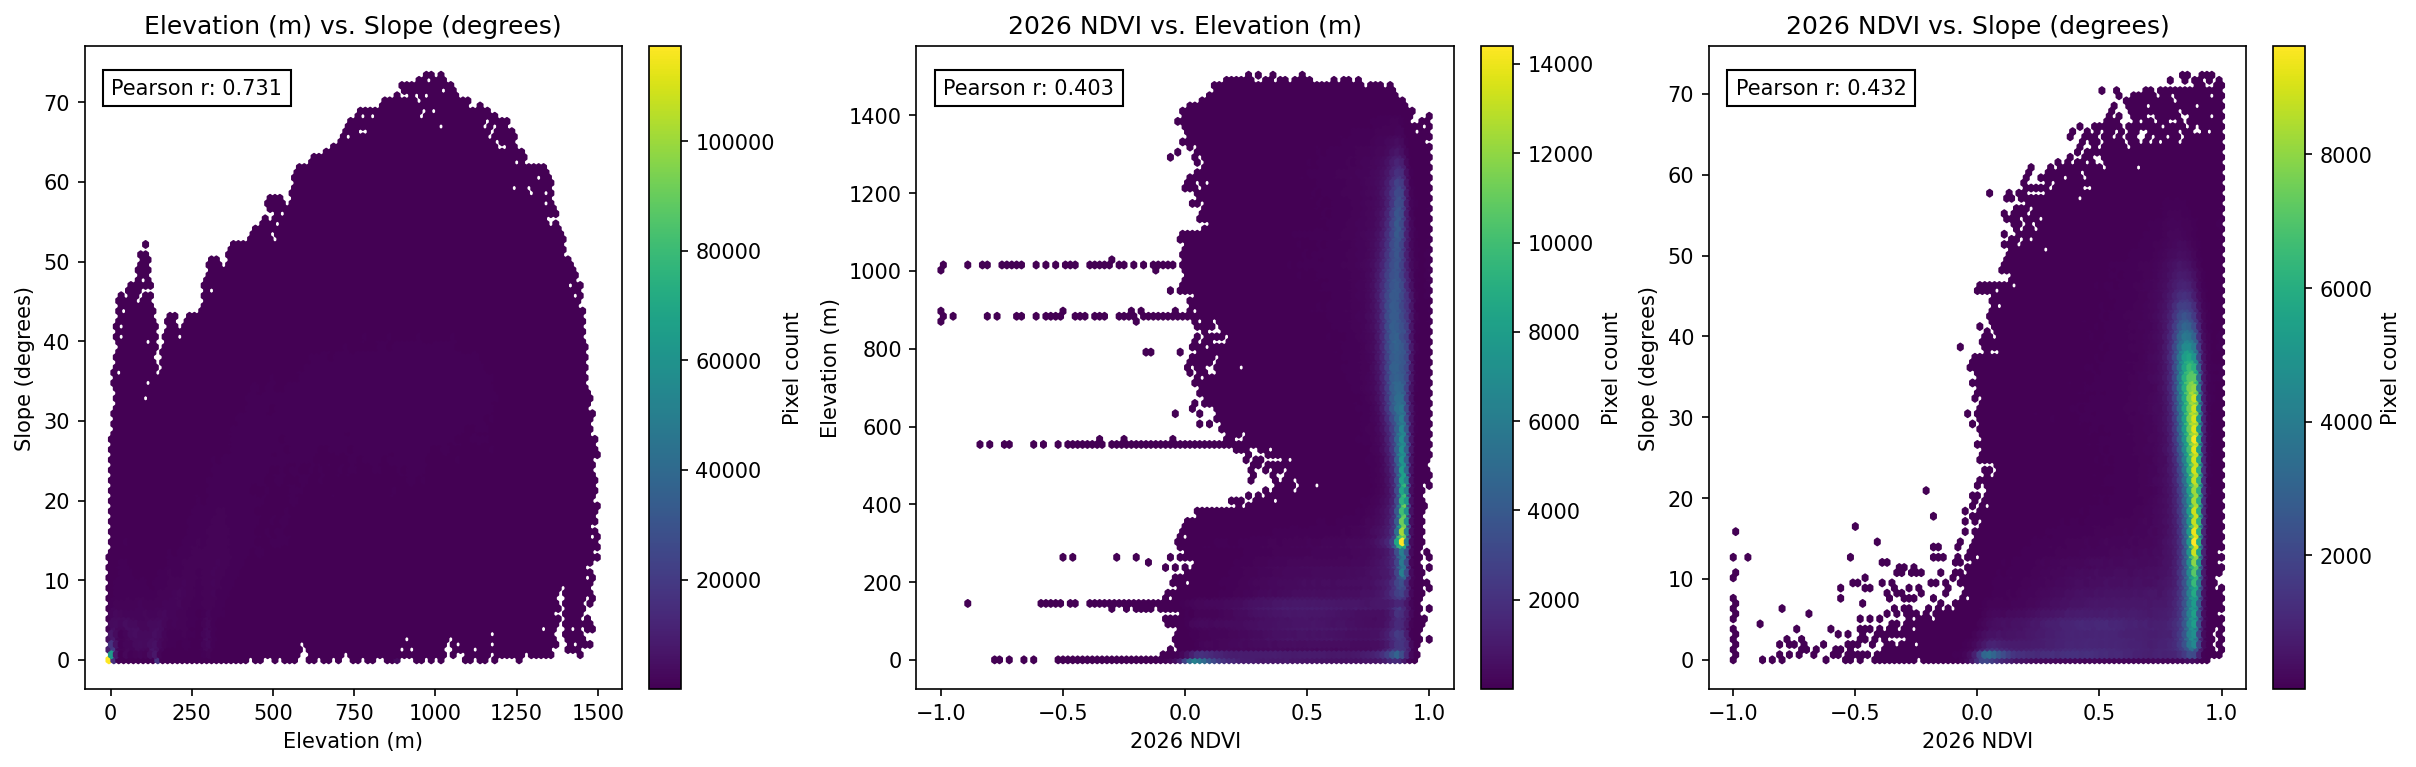

In [317]:
fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), dpi=150, layout="constrained"
)

comparisons = [
    ("Elevation (m)", "Slope (degrees)", elevation_crop, slope_gdal_array),
    ("2026 NDVI", "Elevation (m)", ndvi_2026_crop, elevation_crop),
    ("2026 NDVI", "Slope (degrees)", ndvi_2026_crop, slope_gdal_array),
]

for ax, (x_name, y_name, x_raster, y_raster) in zip(axes, comparisons):

    valid_mask = np.isfinite(x_raster) & np.isfinite(y_raster)
    x = x_raster[valid_mask]
    y = y_raster[valid_mask]

    P_coef = np.corrcoef(x, y)[0, 1]

    hb = ax.hexbin(
        x, y, gridsize=100, mincnt=1, cmap="viridis"
    )
    fig.colorbar(hb, ax=ax, label="Pixel count")

    ax.text(
        0.05, 0.95, f"Pearson r: {P_coef:.3f}",
        transform=ax.transAxes,
        va="top",
        ha="left",
        bbox=dict(facecolor="white", edgecolor="black", alpha=1),
    )

    ax.set_xlabel(x_name)
    ax.set_ylabel(y_name)
    ax.set_title(f"{x_name} vs. {y_name}")

    print(
        f"Pearson correlation ({x_name} vs. {y_name}): "
        f"{P_coef:.3f} | Valid pixels: {len(x)}"
    )

plt.show()

In [ ]:
NDVI_plots = sns.pairplot(
    plot_df_corr,
    vars=feature_names,
    hue="Cluster",
    corner=True,
    plot_kws={"alpha": 0.35, "s": 8},
    diag_kind="hist",
)

for i, j in zip(*np.tril_indices(len(feature_names), k=-1)):
    ax = corr_plots.axes[i, j]
    r = corr.iloc[i, j]

    ax.annotate(
                    f"r = {r:.2f}",
                    xy=(0.05, 0.95),
                    xycoords="axes fraction",
                    ha="left",
                    va="top",
                    fontsize=9,
                    bbox=dict(
                        facecolor="white",
                        alpha=0.8,
                        edgecolor="none"
                    )
                )
    
plt.show()

#### K-Means Analysis

In [155]:
valid_ndvi_temporal = (
    np.isfinite(ndvi_2024_crop)
    & np.isfinite(ndvi_2025_crop)
    & np.isfinite(ndvi_2026_crop)
)

valid_ndvi_2024_mask = ndvi_2024_crop[valid_ndvi_temporal]
valid_ndvi_2025_mask = ndvi_2025_crop[valid_ndvi_temporal]
valid_ndvi_2026_mask = ndvi_2026_crop[valid_ndvi_temporal]

reshaped_ndvi_2024 = valid_ndvi_2024_mask.reshape(-1, 1)
reshaped_ndvi_2025 = valid_ndvi_2025_mask.reshape(-1, 1)
reshaped_ndvi_2026 = valid_ndvi_2026_mask.reshape(-1, 1)

print("NaN count:", np.isnan(valid_ndvi_2024_mask).sum())
print("NaN count:", np.isnan(valid_ndvi_2025_mask).sum())
print("NaN count:", np.isnan(valid_ndvi_2026_mask).sum())

ndvi_all = np.concatenate([reshaped_ndvi_2024, reshaped_ndvi_2025, reshaped_ndvi_2026])
valid_ndvi_2024_mask.shape

NaN count: 0
NaN count: 0
NaN count: 0


(2310894,)

In [156]:
from sklearn.cluster import KMeans

model = KMeans(n_clusters=4, random_state=42, n_init="auto")
model.fit(ndvi_all)

,n_clusters,4
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [158]:
cluster_map_2024 = np.full(ndvi_2024_crop.shape, np.nan)
cluster_map_2025 = np.full(ndvi_2025_crop.shape, np.nan)
cluster_map_2026 = np.full(ndvi_2026_crop.shape, np.nan)

cluster_map_2024[valid_ndvi_temporal] = model.predict(reshaped_ndvi_2024)
cluster_map_2025[valid_ndvi_temporal] = model.predict(reshaped_ndvi_2025)
cluster_map_2026[valid_ndvi_temporal] = model.predict(reshaped_ndvi_2026)

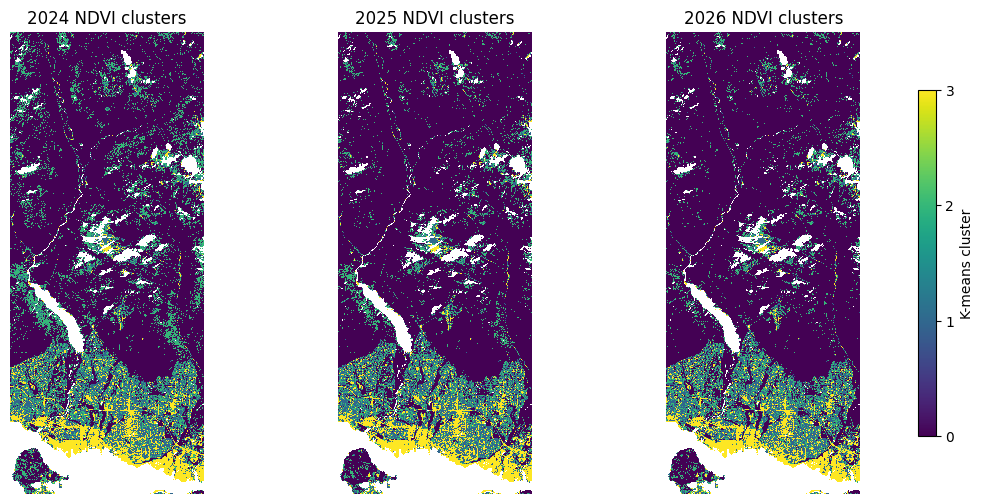

In [159]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6), dpi=100)

for ax, (year, cluster_map) in zip(
    axes,
    [
        ("2024", cluster_map_2024),
        ("2025", cluster_map_2025),
        ("2026", cluster_map_2026)
    ]
):
    im = ax.imshow(
        cluster_map,
        cmap="viridis",
        vmin=0,
        vmax=model.n_clusters - 1,
        interpolation="nearest"
    )
    ax.set_title(f"{year} NDVI clusters")
    ax.axis("off")

fig.colorbar(
    im, ax=axes, ticks=range(model.n_clusters),
    label="K-means cluster", shrink=0.75
)

plt.show()

In [164]:
for label, center in enumerate(model.cluster_centers_.ravel()):
    print(f"Cluster {label}: center NDVI = {center:.3f}")

Cluster 0: center NDVI = 0.867
Cluster 1: center NDVI = 0.445
Cluster 2: center NDVI = 0.709
Cluster 3: center NDVI = 0.143


In [195]:
counts_2024 = np.bincount(
    cluster_map_2024[np.isfinite(cluster_map_2024)].astype(int),
    minlength=model.n_clusters,
)
counts_2025 = np.bincount(
    cluster_map_2025[np.isfinite(cluster_map_2025)].astype(int),
    minlength=model.n_clusters,
)
counts_2026 = np.bincount(
    cluster_map_2026[np.isfinite(cluster_map_2026)].astype(int),
    minlength=model.n_clusters,
)

change_2024_2025_pct = np.divide(
    counts_2025 - counts_2024,
    counts_2024,
    out=np.full(model.n_clusters, np.nan),
    where=counts_2024 != 0,
) * 100

change_2025_2026_pct = np.divide(
    counts_2026 - counts_2025,
    counts_2025,
    out=np.full(model.n_clusters, np.nan),
    where=counts_2025 != 0,
) * 100

change_2024_2026_pct = np.divide(
    counts_2026 - counts_2024,
    counts_2024,
    out=np.full(model.n_clusters, np.nan),
    where=counts_2024 != 0,
) * 100

cluster_counts = pd.DataFrame({
    "2024": counts_2024,
    "2025": counts_2025,
    "2026": counts_2026,
    "2024-2025 % Change": change_2024_2025_pct,
    "2025-2026 % Change": change_2025_2026_pct,
    "2024-2026 % Change": change_2024_2026_pct,
}, index=[f"Cluster {i}" for i in range(model.n_clusters)])

def color_change(value):
    if pd.isna(value) or value == 0:
        return ""
    return "background-color: #d9534f; color: white;" if value < 0 else "background-color: #5cb85c; color: white;"



target_cols = ["2024-2025 % Change", "2025-2026 % Change", "2024-2026 % Change"]
cluster_counts
cluster_counts.style.map(
    color_change,
    subset=[
        "2024-2025 % Change",
        "2025-2026 % Change",
        "2024-2026 % Change",
    ],
).format(
    lambda x: f"{abs(x):.2f}%" if pd.notna(x) else "", # Converts display to absolute values
    subset=target_cols
)

,2024,2025,2026,2024-2025 % Change,2025-2026 % Change,2024-2026 % Change
Cluster 0,1573646,1722286,1737403,9.45%,0.88%,10.41%
Cluster 1,218601,204596,205536,6.41%,0.46%,5.98%
Cluster 2,374032,244743,239100,34.57%,2.31%,36.07%
Cluster 3,144615,139269,128855,3.70%,7.48%,10.90%


#### Kmeans Clustering Correlation **

In [197]:
from sklearn.preprocessing import StandardScaler

features = np.stack(
    [
        ndvi_2024_crop,
        ndvi_2025_crop,
        ndvi_2026_crop,
        elevation_crop,
        slope_gdal_array
    ],
    axis = -1
)

valid_mask_features = np.all(np.isfinite(features), axis=-1)
finite_training_features = features[valid_mask_features]

scaler = StandardScaler()
features_scaled = scaler.fit_transform(finite_training_features)

print("Feature matrix:", finite_training_features.shape)
print("Standardized matrix:", features_scaled.shape)

Feature matrix: (2282690, 5)
Standardized matrix: (2282690, 5)


In [230]:
model_cluster_corr = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

2282690


In [309]:
cluster_labels = model_cluster_corr .fit_predict(features_scaled)

cluster_map = np.full(
    valid_mask_features.shape,
    np.nan,
    dtype=np.float32
)
cluster_map[valid_mask_features] = cluster_labels

In [314]:
centres_cluster_corr = scaler.inverse_transform(model_cluster_corr.cluster_centers_)

feature_names = [
    "NDVI 2024", "NDVI 2025", "NDVI 2026",
    "Elevation (m)", "Slope (degrees)"
]

cluster_centres_df = pd.DataFrame(
    centres_cluster_corr, 
    columns=feature_names,
    index=[f"Cluster {i}" for i in range(model_cluster_corr.n_clusters)],
)

df_corr = pd.DataFrame(finite_training_features, columns=feature_names)
df_corr["Cluster"] = cluster_labels

cluster_corr_data = df_corr.sample(
    n=min(5000, len(df_corr)),
    random_state=42,
)
pears_corr = df_corr[feature_names].corr(method="pearson")

cluster_corr_stats = pd.concat(
    {
        "Cluster centers": cluster_corr_data,
        "Pearson correlations": pears_corr,
    },
    names=["Statistic", "Row"],
)

cluster_corr_stats.round(3)

NDVI 2024  NDVI 2025  NDVI 2026  \
Statistic            Row                                                
Cluster centers      2257936              0.024      0.030      0.036   
                     1124570              0.762      0.789      0.802   
                     2066403              0.632      0.618      0.674   
                     1044116              0.847      0.871      0.868   
                     757596               0.886      0.908      0.896   
...                                         ...        ...        ...   
Pearson correlations NDVI 2024            1.000      0.974      0.975   
                     NDVI 2025            0.974      1.000      0.983   
                     NDVI 2026            0.975      0.983      1.000   
                     Elevation (m)        0.405      0.411      0.410   
                     Slope (degrees)      0.418      0.435      0.437   

                                      Elevation (m)  Slope (degrees)  Cluster  
Statistic            Row                                                       
Cluster centers      2257936                  4.230            0.267      3.0  
                     1124570               1279.461           38.630      0.0  
                     2066403                131.988            0.860      1.0  
                     1044116                707.268           43.744      0.0  
                     757596                 398.493           20.680      2.0  
...                                             ...              ...      ...  
Pearson correlations NDVI 2024                0.405            0.418      NaN  
                     NDVI 2025                0.411            0.435      NaN  
                     NDVI 2026                0.410            0.437      NaN  
                     Elevation (m)            1.000            0.693      NaN  
                     Slope (degrees)          0.693            1.000      NaN  

[5005 rows x 6 columns]

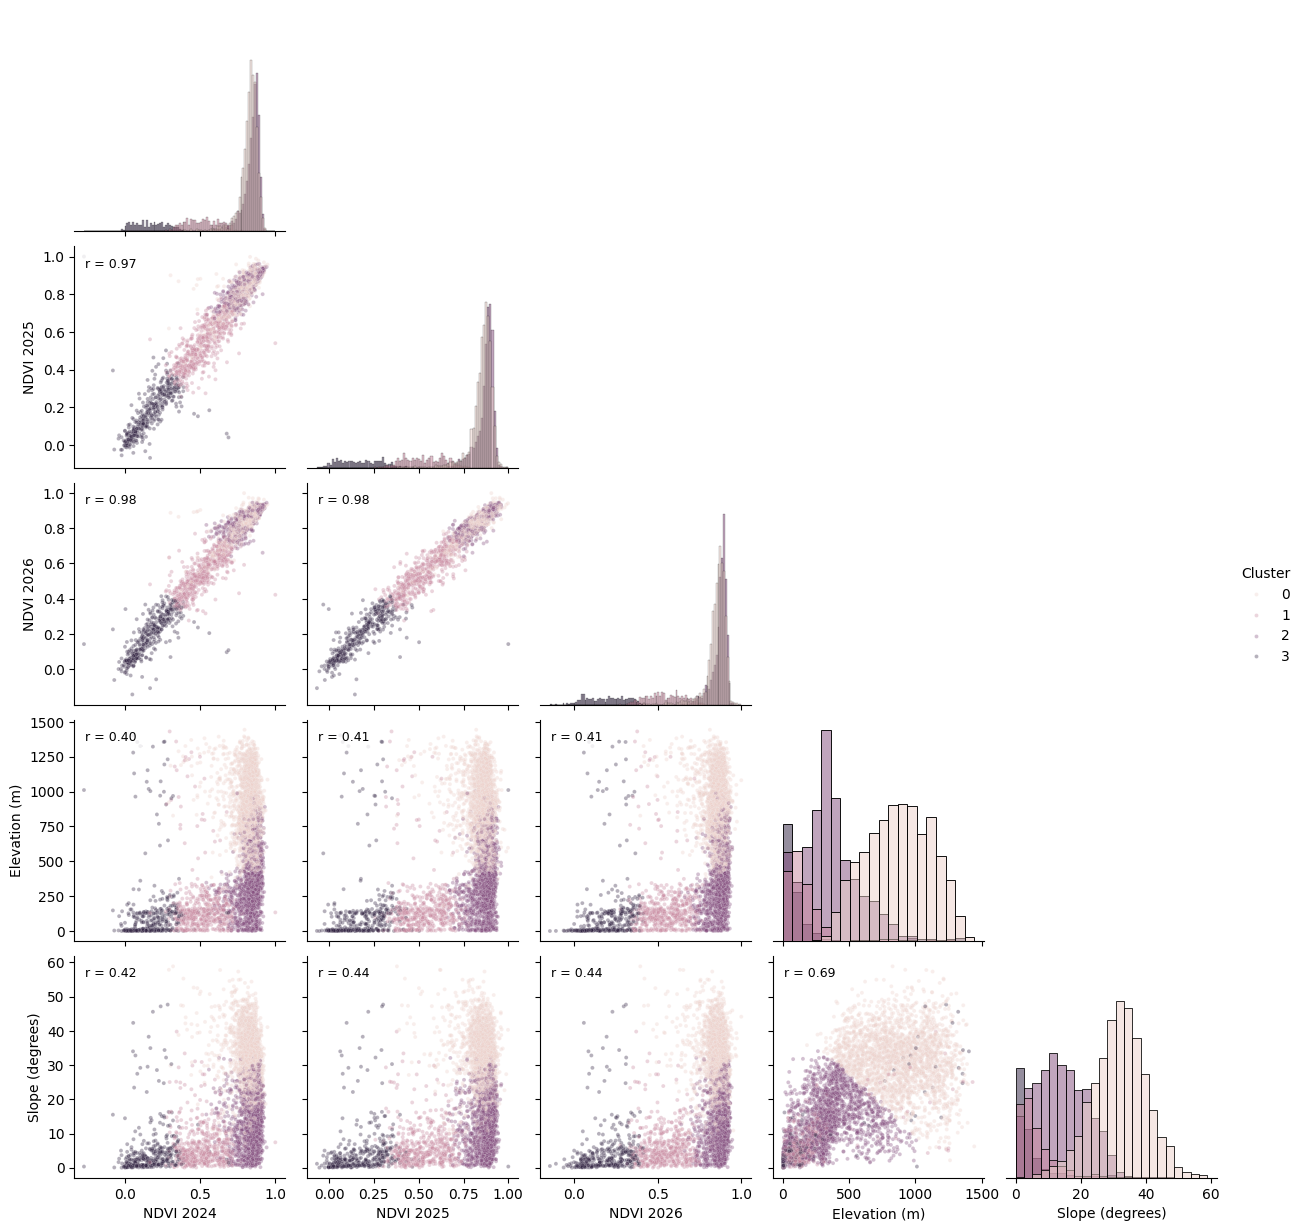

In [315]:
corr_plots = sns.pairplot(
    cluster_corr_data,
    vars=feature_names,
    hue="Cluster",
    corner=True,
    plot_kws={"alpha": 0.35, "s": 8},
    diag_kind="hist",
)

for i, j in zip(*np.tril_indices(len(feature_names), k=-1)):
    ax = corr_plots.axes[i, j]
    r = corr.iloc[i, j]

    ax.annotate(
        f"r = {r:.2f}",
        xy=(0.05, 0.95),
        xycoords="axes fraction",
        ha="left",
        va="top",
        fontsize=9,
        bbox=dict(
        facecolor="white",
        alpha=0.8,
        edgecolor="none"
        )
    )
    
plt.show()

### RandomForest Classification against Dynamic World V1 **

### Band and Blender Exports **

In [65]:
valid_mask_export = (
    np.isfinite(elevation_crop)
    & np.isfinite(slope_gdal_array)
    & np.isfinite(ndvi_2024_crop)
    & np.isfinite(ndvi_2025_crop)
    & np.isfinite(ndvi_2026_crop)
)

rows, cols = np.where(valid_mask_export)

x_clean = rows
y_clean = cols
z_clean = elevation_crop[rows, cols]
slope_clean = slope_gdal_array[rows, cols]
ndvi_2024_clean = ndvi_2024_crop[rows, cols]
ndvi_2025_clean = ndvi_2025_crop[rows, cols]
ndvi_2026_clean = ndvi_2026_crop[rows, cols]

print(
    f"x_clean: {x_clean.shape}\n",
    f"y_clean: {y_clean.shape}\n",
    f"z_clean: {z_clean.shape}\n",
    f"slope_clean: {slope_clean.shape}\n",
    f"ndvi_2024_clean: {ndvi_2024_clean.shape}\n",
    f"ndvi_2025_clean: {ndvi_2025_clean.shape}\n",
    f"ndvi_2026_clean: {ndvi_2026_clean.shape}\n",
)

x_clean: (2282690,)
 y_clean: (2282690,)
 z_clean: (2282690,)
 slope_clean: (2282690,)
 ndvi_2024_clean: (2282690,)
 ndvi_2025_clean: (2282690,)
 ndvi_2026_clean: (2282690,)



In [66]:
origin_x = (x_clean.min() + x_clean.max()) / 2
origin_y = (y_clean.min() + y_clean.max()) / 2
origin_z = z_clean.min()
origin_slope = slope_clean.min()
origin_ndvi_2024_clean = ndvi_2024_clean.min()
origin_ndvi_2025_clean = ndvi_2025_clean.min()
origin_ndvi_2026_clean = ndvi_2026_clean.min()

scale = 100.0  

x_blender = (x_clean - origin_x) / scale
y_blender = (y_clean - origin_y) / scale
z_blender = (z_clean - origin_z) / scale
slope_blender = (slope_clean - origin_slope) / scale
nvdi_2024_blender = (ndvi_2024_clean - origin_ndvi_2024_clean) / scale
ndvi_2025_blender = (ndvi_2025_clean - origin_ndvi_2025_clean) / scale
ndvi_2026_blender = (ndvi_2026_clean - origin_ndvi_2026_clean) / scale

blender_points = np.column_stack((x_blender, y_blender, z_blender, slope_blender, nvdi_2024_blender, ndvi_2025_blender, ndvi_2026_blender))

In [67]:
np.savetxt(
    r"Data Export\terrain_points.csv",
    blender_points,
    delimiter=",",
    header="x,y,z",
    comments=""
)

### Multi-band Export to QGIS **

In [303]:
clean_export_datasets = {
    "NDVI_2024": ndvi_2024_crop,
    "NDVI_2025": ndvi_2025_crop,
    "NDVI_2026": ndvi_2026_crop,
    "DEM": elevation_crop,
    "Slope": slope_gdal_array,
    "DW_v1": dw_crop
}

export_bands = {}
export_bands.update(list(clean_export_datasets.items())[:6])

for name, array in clean_export_datasets.items():
    print(f"Key: {name}, Array Shape: {array.shape}")

export_array_width, export_array_height = clean_export_datasets["NDVI_2024"].shape[0], clean_export_datasets["NDVI_2024"].shape[1]

Key: NDVI_2024, Array Shape: (2486, 1043)
Key: NDVI_2025, Array Shape: (2486, 1043)
Key: NDVI_2026, Array Shape: (2486, 1043)
Key: DEM, Array Shape: (2486, 1043)
Key: Slope, Array Shape: (2486, 1043)
Key: DW_v1, Array Shape: (2486, 1043)
2486 1043


In [305]:
output_path = r"Data Export\export_bands.tif"
crop_transform = sentinel_2026_B4_transform * Affine.translation(col0, row0)

with rasterio.open(output_path, "w",
                   driver="GTiff",
                   height=export_array_height,
                   width=export_array_width,
                   count=len(export_bands),
                   dtype="float32",
                   crs=sentinel_2026_B4_crs,
                   transform=crop_transform,
                   nodata=np.nan) as dst:

    for band_number, (name, raster) in enumerate(export_bands.items(), start=1):
        dst.write(raster.astype("float32"), band_number)
        dst.set_band_description(band_number, name)

# Missed **

- zenith, solar angle, shadow
- zero values for ndvi filter? 
- bug check, top down load check
- fix temporal correlation first charts, not kmeans, maybe use pd there
- aspect
- hillshade